# APA - Lista de Problemas 2: Problema Individual 4

##  La dura vida del estudiante

In [776]:
# Descomentar para actualizar librerias
# Si se actualiza alguna libreria hay que reiniciar el notebook
# !pip install pandas --upgrade  --quiet
# !pip install numpy --upgrade  --quiet
# !pip install scipy --upgrade  --quiet
# !pip install statsmodels --upgrade  --quiet
# !pip install scikit-learn --upgrade  --quiet
!pip install missingno --upgrade  --quiet
!pip install apafib --upgrade --quiet

In [777]:
from IPython.core.interactiveshell import InteractiveShell
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split,  KFold, cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import  ConfusionMatrixDisplay,\
                  classification_report,  RocCurveDisplay, PrecisionRecallDisplay,\
                    accuracy_score, f1_score, precision_score, recall_score
from yellowbrick.target.feature_correlation import feature_correlation
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
InteractiveShell.ast_node_interactivity = "all"

from time import time
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pandas.plotting import scatter_matrix
init_time = time()

In [778]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.precision', 3)

In [779]:
def save_results(clf, X_test, y_test, nclf, df):
    if hasattr(clf, 'best_score_'):
        df.loc[nclf,'train XV acc'] = clf.best_score_
    else:
        df.loc[nclf,'train XV acc'] = np.nan
    df.loc[nclf,'test acc'] = accuracy_score(y_test, clf.predict(X_test))
    df.loc[nclf,'precision score (M)'] = precision_score(y_test, clf.predict(X_test), average='macro')
    df.loc[nclf,'recall score (M)'] = recall_score(y_test, clf.predict(X_test), average='macro')
    df.loc[nclf,'f1 score (M)'] = f1_score(y_test, clf.predict(X_test), average='macro')
    return df

results_df = pd.DataFrame()

niter = 15
cv = 5

## APARTADO A

### CARGA DE DATOS Y VISUALIZACIÓN

Cargamos los datos y separamos la variable objetivo (`Stress Label`) del conjunto de datos.

In [780]:
from apafib import load_stress

# Cargamos el DataFrame
data = load_stress()

print(data.columns)

Index(['1. Age', '2. Gender', '5. Academic Year', '6. Current CGPA',
       '7. Did you receive a waiver or scholarship at your university?',
       '1. In a semester, how often have you felt upset due to something that happened in your academic affairs? ',
       '2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?',
       '3. In a semester, how often you felt nervous and stressed because of academic pressure? ',
       '4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams) ',
       '5. In a semester, how often you felt confident about your ability to handle your academic / university problems?',
       '6. In a semester, how often you felt as if things in your academic life is going on your way? ',
       '7. In a semester, how often are you able to control irritations in your academic / university affairs? ',
       '8. In a semester, how

Como vemos, hay variables cuyo nombre son preguntas bastante largas. Para que las tablas y los grafos sean más legibles de cara a los apartados del problema, renombramos las variables a nombres más cortos (palabras claves de las preguntas).

In [781]:
new_names = {
    '1. Age': 'Age',
    '2. Gender': 'Gender',
    '5. Academic Year': 'Academic_Year',
    '6. Current CGPA': 'CGPA',
    '7. Did you receive a waiver or scholarship at your university?': 'Scholarship',
    '1. In a semester, how often have you felt upset due to something that happened in your academic affairs? ': 'Q1_Upset_Lvl',
    '2. In a semester, how often you felt as if you were unable to control important things in your academic affairs?': 'Q2_Unable_Control',
    '3. In a semester, how often you felt nervous and stressed because of academic pressure? ': 'Q3_Stressed_Lvl',
    '4. In a semester, how often you felt as if you could not cope with all the mandatory academic activities? (e.g, assignments, quiz, exams) ': 'Q4_Cannot_Cope',
    '5. In a semester, how often you felt confident about your ability to handle your academic / university problems?': 'Q5_Confidence_Lvll',
    '6. In a semester, how often you felt as if things in your academic life is going on your way? ': 'Q6_ThingsMyWay_Lvl',
    '7. In a semester, how often are you able to control irritations in your academic / university affairs? ': 'Q7_ControlIrritations_Lvl',
    '8. In a semester, how often you felt as if your academic performance was on top?': 'Q8_PerformanceOnTop_lvl',
    '9. In a semester, how often you got angered due to bad performance or low grades that is beyond your control? ': 'Q9_Anger_Lvl',
    '10. In a semester, how often you felt as if academic difficulties are piling up so high that you could not overcome them? ': 'Q10_DifficultiesPiling_Lvl',
    'Stress Label': 'Stress Label'
}

data = data.rename(columns=new_names)
print(data.columns)

Index(['Age', 'Gender', 'Academic_Year', 'CGPA', 'Scholarship', 'Q1_Upset_Lvl',
       'Q2_Unable_Control', 'Q3_Stressed_Lvl', 'Q4_Cannot_Cope',
       'Q5_Confidence_Lvll', 'Q6_ThingsMyWay_Lvl', 'Q7_ControlIrritations_Lvl',
       'Q8_PerformanceOnTop_lvl', 'Q9_Anger_Lvl', 'Q10_DifficultiesPiling_Lvl',
       'Stress Label'],
      dtype='object')


Una vez renombrados, separamos la variable objetivo del conjunto de datos y hacemos una primera visualización de los datos.

In [782]:
# Separamos la variable objetivo del conjunto de datos
X = data.drop(columns=['Stress Label'])
y = data['Stress Label']

X.head()

,Age,Gender,Academic_Year,CGPA,Scholarship,Q1_Upset_Lvl,Q2_Unable_Control,Q3_Stressed_Lvl,Q4_Cannot_Cope,Q5_Confidence_Lvll,Q6_ThingsMyWay_Lvl,Q7_ControlIrritations_Lvl,Q8_PerformanceOnTop_lvl,Q9_Anger_Lvl,Q10_DifficultiesPiling_Lvl
0,18-22,Female,Fourth Year or Equivalent,2.50 - 2.99,No,2,2,3,2,2,2,2,2,2,2
1,18-22,Male,First Year or Equivalent,3.80 - 4.00,No,2,2,2,2,2,2,2,1,1,2
2,18-22,Male,First Year or Equivalent,3.00 - 3.39,No,3,2,2,3,3,2,3,2,2,1
3,18-22,Male,First Year or Equivalent,3.40 - 3.79,No,2,2,2,2,2,2,2,2,2,2
4,18-22,Male,First Year or Equivalent,3.40 - 3.79,No,2,2,2,2,2,2,2,2,2,2


In [783]:
X.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1977,5,18-22,1273,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1977,3,Male,1372,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic_Year,1977,5,First Year or Equivalent,592,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CGPA,1977,6,3.00 - 3.39,572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Scholarship,1977,2,No,1571,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q1_Upset_Lvl,1977.0,NaN,NaN,NaN,2.342,1.179,0.0,2.0,2.0,3.0,4.0
Q2_Unable_Control,1977.0,NaN,NaN,NaN,2.32,1.155,0.0,2.0,2.0,3.0,4.0
Q3_Stressed_Lvl,1977.0,NaN,NaN,NaN,2.706,1.135,0.0,2.0,3.0,4.0,4.0
Q4_Cannot_Cope,1977.0,NaN,NaN,NaN,2.361,1.224,0.0,2.0,2.0,3.0,4.0
Q5_Confidence_Lvll,1977.0,NaN,NaN,NaN,1.825,1.085,0.0,1.0,2.0,2.0,4.0


TODO:
A partir de estas tablas podemos ver con que tipo de variables trabajaremos. Este conjunto cuenta con X variables categóricas, Y...

Respecto a la variable objetivo, podemos mirar como se distribuyen sus 3 valores en el conjunto de datos:

In [784]:
y.value_counts()

Stress Label
Moderate Stress          1316
High Perceived Stress     546
Low Stress                115
Name: count, dtype: int64

Vemos que más de la mitad de los estudiantes (un 66%) sufre un nivel de estrés medio, un 27% sufre un nivel de estrés alto y tan solo un 7% de los estudiantes sufre poco estrés.

Antes de hacer cualquier estudio de los datos miramos si hay valores perdidos:

In [785]:
data.isna().sum()

Age                           0
Gender                        0
Academic_Year                 0
CGPA                          0
Scholarship                   0
Q1_Upset_Lvl                  0
Q2_Unable_Control             0
Q3_Stressed_Lvl               0
Q4_Cannot_Cope                0
Q5_Confidence_Lvll            0
Q6_ThingsMyWay_Lvl            0
Q7_ControlIrritations_Lvl     0
Q8_PerformanceOnTop_lvl       0
Q9_Anger_Lvl                  0
Q10_DifficultiesPiling_Lvl    0
Stress Label                  0
dtype: int64

Al ver que no hay valores perdidos que tengamos que imputar, ya podemos pasar a entrenar el conjunto y empezar su exploración.

### División entrenamiento y test
Particionamos los datos en 2 conjuntos, entrenamiento y test (70% y 30% respectivamente). 

Tal y como se especifica en el enunciado usaremos una partición estratificada, para que haya aproximadamente la misma proporción de ejemplos de cada clase en cada partición y fijaremos el `random_state` con un valor distinto de cero para la reproducibilidad.

In [786]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

A continuación, generaremos dos conjuntos de datos, uno en el que haremos codificación numérica de las variables categóricas y otro en el que binarizemos las variables.

Primero identificamos las columnas categóricas que necesitan transformación mediante:

In [787]:
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
print(cat_cols)

Index(['Age', 'Gender', 'Academic_Year', 'CGPA', 'Scholarship'], dtype='object')


Para transformar el primer cojunto (codificación númerica) codificamos las categorías de estas variables en números secuenciales. Para lograrlo, definimos un diccionario para cada una de las 5 variables con el objetivo de mantener el orden lógico de cada una.

In [788]:
# Creamos copias para preservar los datos originales
X_train_num = X_train.copy()
X_test_num = X_test.copy()

age_map = {'Below 18': 0, '18-22': 1, '23-26': 2, '27-30': 3, 'Above 30': 4}
gender_map = {'Female': 0, 'Male': 1, 'Prefer not to say': 2}
year_map = {'First Year or Equivalent': 0, 'Second Year or Equivalent': 1, 
            'Third Year or Equivalent': 2, 'Fourth Year or Equivalent': 3, 'Other': 4}
cgpa_map = {'Below 2.50': 0, '2.50 - 2.99': 1, '3.00 - 3.39': 2, '3.40 - 3.79': 3, '3.80 - 4.00': 4, 'Other': 5}
scholarship_map = {'No': 0, 'Yes': 1}

# Aplicamos el mapeo a los conjuntos
for df in [X_train_num, X_test_num]:
    df['Age'] = df['Age'].map(age_map)
    df['Gender'] = df['Gender'].map(gender_map)
    df['Academic_Year'] = df['Academic_Year'].map(year_map)
    df['CGPA'] = df['CGPA'].map(cgpa_map)
    df['Scholarship'] = df['Scholarship'].map(scholarship_map)

X_train_num.head()

,Age,Gender,Academic_Year,CGPA,Scholarship,Q1_Upset_Lvl,Q2_Unable_Control,Q3_Stressed_Lvl,Q4_Cannot_Cope,Q5_Confidence_Lvll,Q6_ThingsMyWay_Lvl,Q7_ControlIrritations_Lvl,Q8_PerformanceOnTop_lvl,Q9_Anger_Lvl,Q10_DifficultiesPiling_Lvl
1660,1,0,1,2,0,4,4,4,4,3,3,2,4,4,4
1513,1,0,2,4,0,4,3,4,4,3,3,3,3,3,4
709,2,1,3,2,0,2,2,2,1,1,0,2,1,2,2
1964,2,0,3,1,0,4,4,4,4,0,0,0,0,4,4
1016,1,1,0,5,0,2,2,3,2,2,2,3,2,0,1


Podemos observar que las 5 variables categóricas han sido transformadas correctamente (ahora tienen valores numéricos).

A continuación codificamos de nuevo el conjuto original, pero esta vez aplicando One-Hot Encoding para generar el segundo conjunto pedido en el enunciado (conjunto binarizado).

In [789]:
X_train_bin = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_bin = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

# Alinear las columnas del conjunto de test con las de entrenamiento.
X_train_bin, X_test_bin = X_train_bin.align(X_test_bin, join='left', axis=1, fill_value=0)
X_train_bin.head()

,Q1_Upset_Lvl,Q2_Unable_Control,Q3_Stressed_Lvl,Q4_Cannot_Cope,Q5_Confidence_Lvll,Q6_ThingsMyWay_Lvl,Q7_ControlIrritations_Lvl,Q8_PerformanceOnTop_lvl,Q9_Anger_Lvl,Q10_DifficultiesPiling_Lvl,Age_23-26,Age_27-30,Age_Above 30,Age_Below 18,Gender_Male,Gender_Prefer not to say,Academic_Year_Fourth Year or Equivalent,Academic_Year_Other,Academic_Year_Second Year or Equivalent,Academic_Year_Third Year or Equivalent,CGPA_3.00 - 3.39,CGPA_3.40 - 3.79,CGPA_3.80 - 4.00,CGPA_Below 2.50,CGPA_Other,Scholarship_Yes
1660,4,4,4,4,3,3,2,4,4,4,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0
1513,4,3,4,4,3,3,3,3,3,4,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
709,2,2,2,1,1,0,2,1,2,2,1,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0
1964,4,4,4,4,0,0,0,0,4,4,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1016,2,2,3,2,2,2,3,2,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0


Las cinco variables categóricas han sido binarizadas correctamente.


Ahora podemos pasar a hacer una visualización mínima de las variables, empezando con un heatmap para ver las correlaciones entre ellas.

Para empezar, lo haremos con el conjunto codificado numéricamente (ya que incluye las variables que antes eran categóricas) y le añadiremos la variable objetivo (codificada también).

<Figure size 1400x1000 with 0 Axes>

<Axes: >

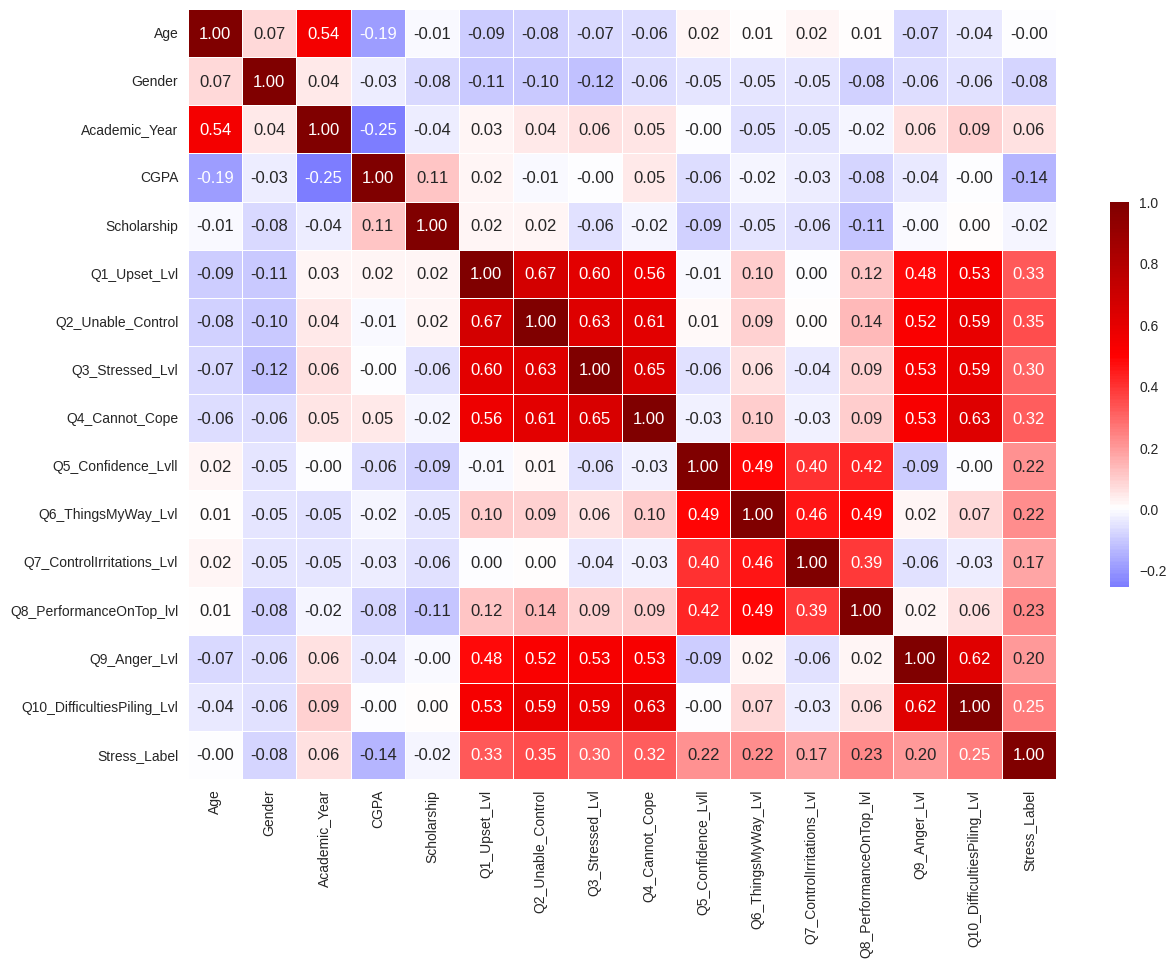

In [790]:
# Codificación numérica de la variable objetivo
target_map = {'Low Stress': 0, 'Moderate Stress': 1, 'High Stress': 2}
y_train_num = y_train.map(target_map)

# Copia del conjunto codificado numéricamente + variable objetivo
train_data_num = X_train_num.copy()
train_data_num['Stress_Label'] = y_train_num


plt.figure(figsize=(14, 10))
corr_matrix = train_data_num.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='seismic', center=0, fmt=".2f",
            linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

Al estudiar los resultados de la matriz de correlación, podemos ver que hay fuertes relaciones entre varias variables.

En primer lugar, podemos ver que hay correlaciones marcadas con la variable objetivo (`Stress_Label`), aunque no son principalmente altas. Por ejemplo, la sensación de no poder controlar las cosas (`Q2_Unable_Control`) muestra la mayor correlación lineal positiva (0.35) con el nivel de estrés, seguida muy de cerca por sentirse molesto/nervioso (`Q1_Upset_Lvl`) con 0.33 y la incapacidad para afrontar problemas (`Q4_Cannot_Cope`) con 0.32. De forma opuesta, tener una mejor nota media (`CGPA`) tiene un impacto negativo (-0.14) sobre el nivel de estrés.

Las correlaciones más fuertes se encuentran entre variables predictoras. Por ejemplo, existe una correlación muy alta entre las distintas preguntas que miden los niveles de estado psicológico: `Q1_Upset_Lvl` y `Q2_Unable_Control` tienen una correlación de 0.67, mientras que `Q3_Stressed_Lvl` y `Q4_Cannot_Cope` llegan a un 0.65. Además, también se observa una correlación positiva alta (0.54) entre la edad (`Age`) y el año académico (`Academic_Year`), cosa que tiene mucho sentido.

Hacer el heatmap con el conjunto binarizado no nos aportará demasiada información nueva, ya cada variable categórica se ha dividido en múltiples variables binarias. Pero podemos hacerlo para ver si hay valores concretos en una misma variable (variable categórica del conjunto original) que se relacionan más con algunas variables. Como antes, añadimos primero la variable objetivo al conjunto (usamos la misma variable codificada `y_train_num`).

<Figure size 2000x1600 with 0 Axes>

<Axes: >

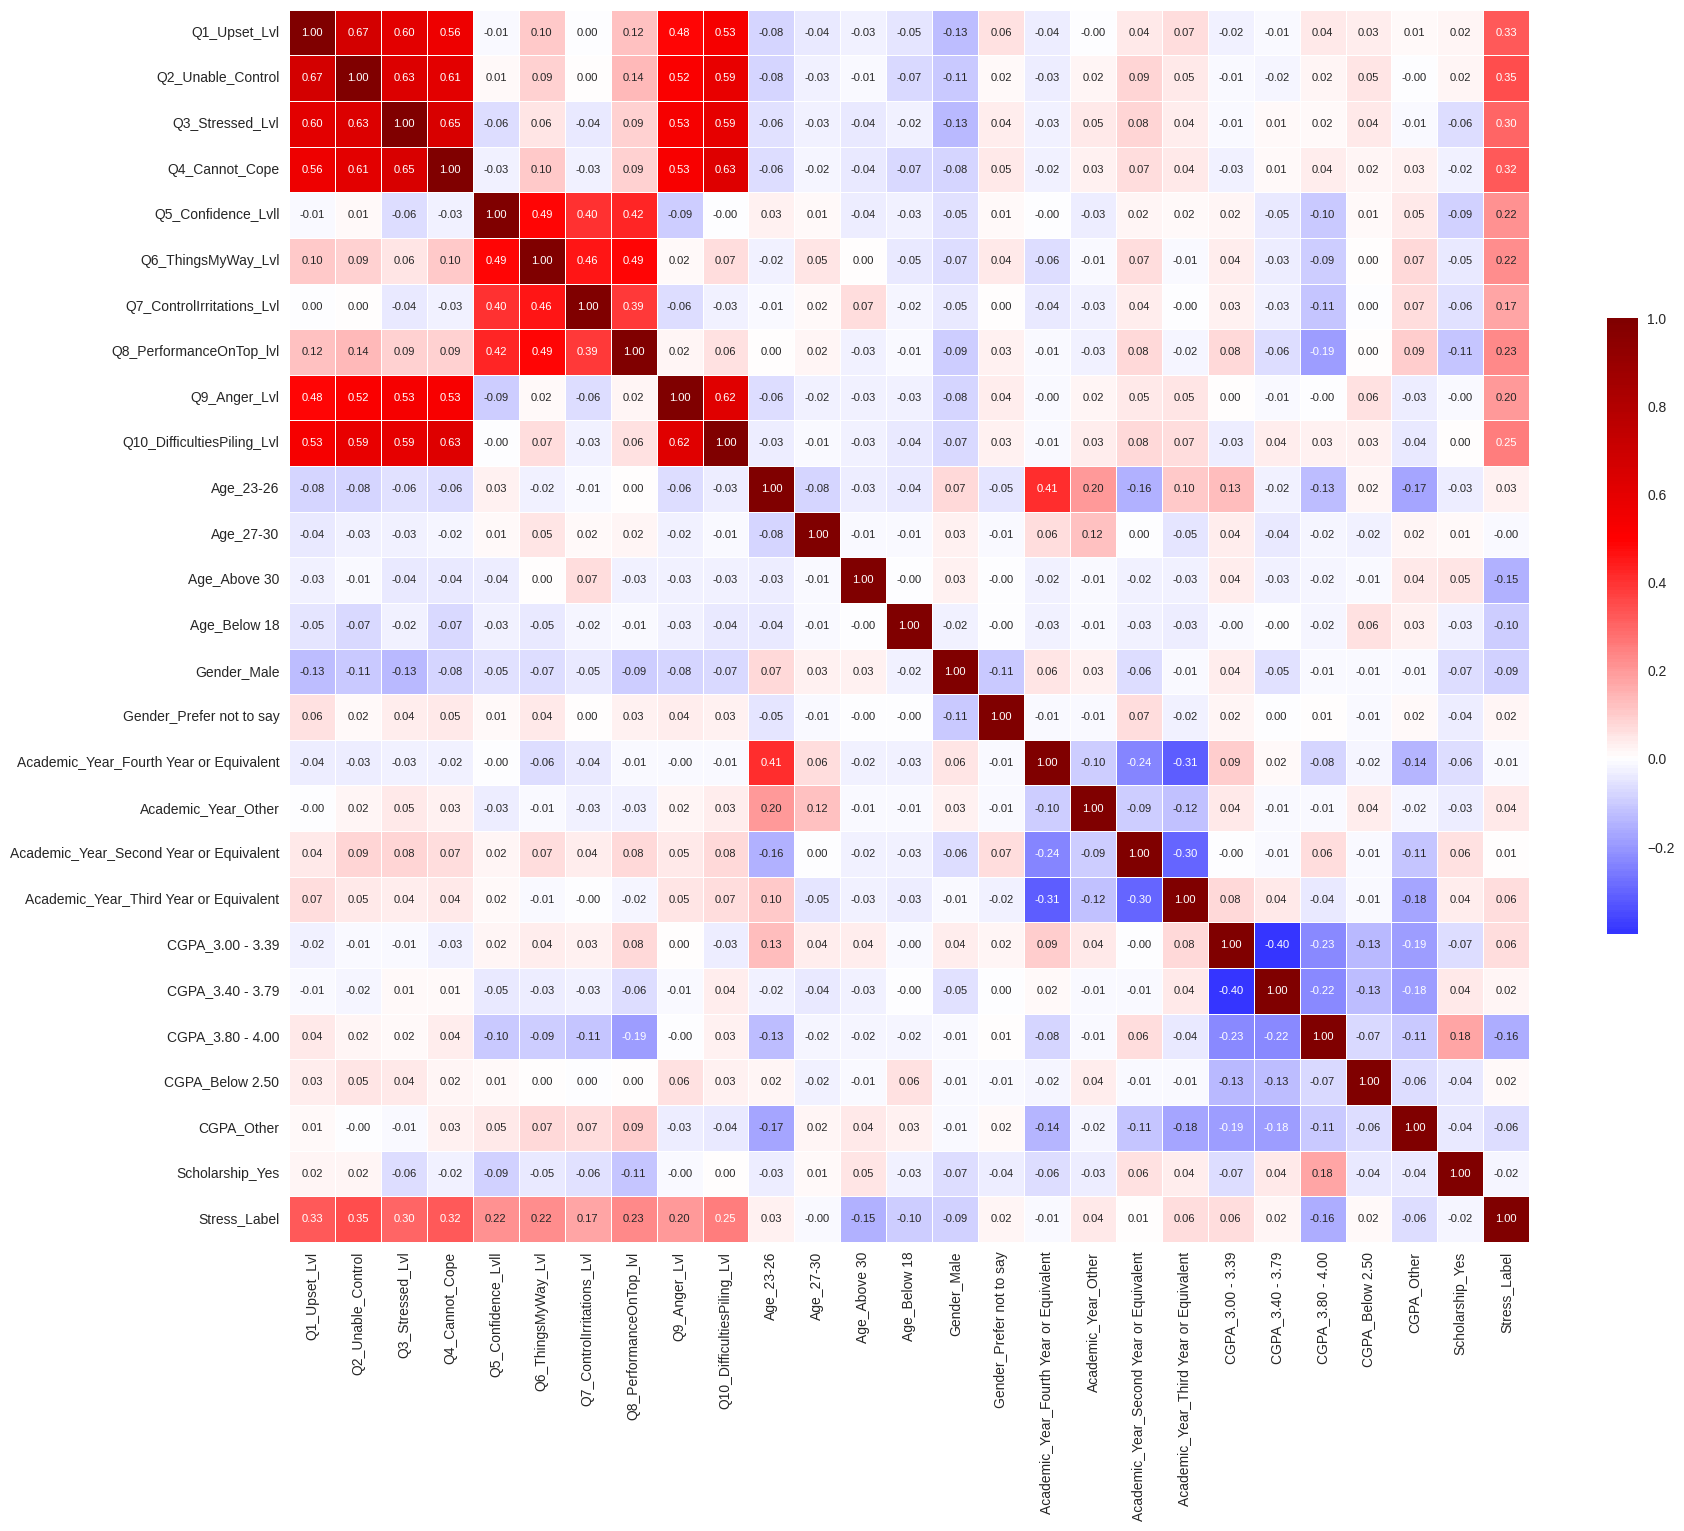

In [791]:
# Copia del conjunto Binarizado + variable objetivo
train_data_bin = X_train_bin.copy()
train_data_bin['Stress_Label'] = y_train_num


plt.figure(figsize=(20, 16))
corr_matrix_bin = train_data_bin.corr(numeric_only=True)
sns.heatmap(corr_matrix_bin, annot=True, cmap='seismic', center=0, fmt=".2f",
            linewidths=.5, cbar_kws={"shrink": .5}, annot_kws={"size": 8})
plt.show()

Al expandir las variables categóricas mediante binarización, el mapa de correlación no revela demasiada información nueva, ya que los principales grupos de correlaciones altas se encuentran en las preguntas del cuestionario mencionadas anteriormente.

Sin embargo, podemos reforzar algunas de las conclusiones que dijimos antes y añadir algunas nuevas. Por ejemplo, pertenecer al grupo de las mejores calificaciones (`CGPA_3.80 - 4.00`) presenta una correlación negativa de -0.16 con el estrés, pero (aunque no muy fuerte) tiene una correlación positiva muy lógica con tener beca (`Scolarship_Yes`). De manera similar, los estudiantes de edad entre 23-26 (`Age_23-26`) muestran un fuerte impacto positivo (0.41) con estar en el cuarto curso académico, una correlación probablemente compartida con edades de 18-22 (categoría eliminada en el One-Hot Encoding por ser la categoría base o de referencia). 

Para los histogramas podríamos seleccionar el conjunto codificado numéricamente (`X_train_num`) pero como el conjunto original `data` contiene la variable objetivo y las variables categóricas, será más fácil entender las gráficas a partir de éste último (de todos modos los resultados serían los mismos). No tiene sentido hacerlo con el conjunto binarizado porque obtendríamos una gráfica por cada variable transformada con One-Hot Encoding, y cada una de ésta tendría únicamente 1 valor en ella.

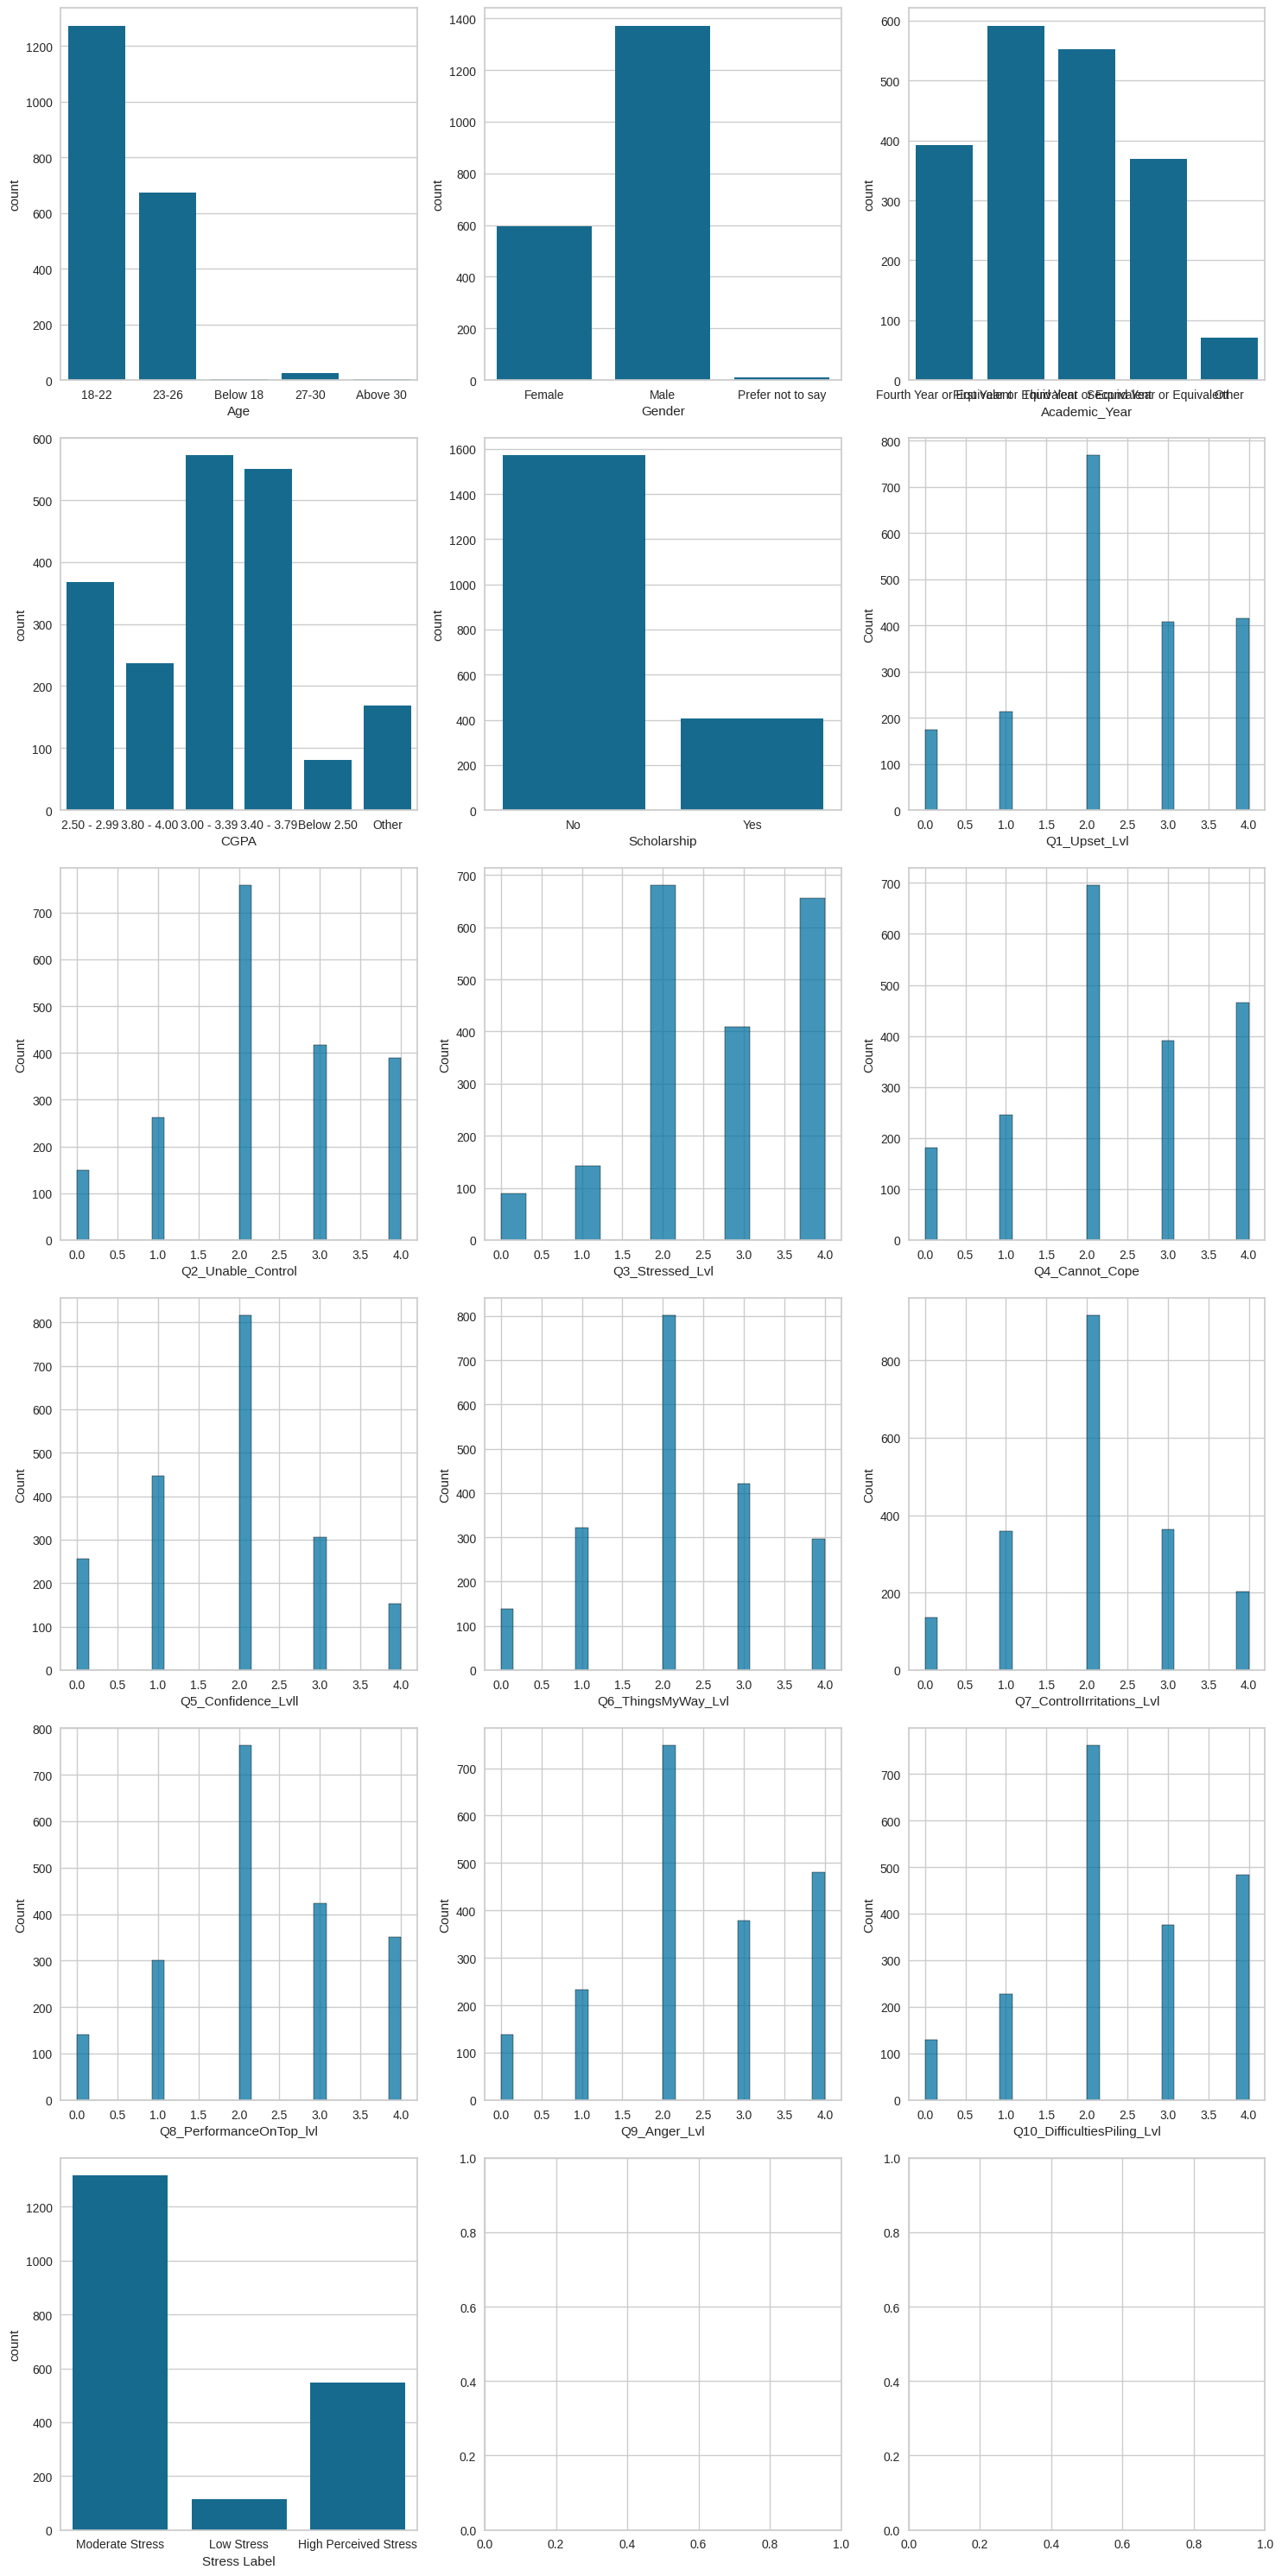

In [792]:
fig, axes = plt.subplots(6,3,figsize=(15,30))

X_train_frame = pd.DataFrame(data)
X_train_frame.columns=data.columns
for i, c in enumerate(data.columns):
    ax = axes.reshape(-1)[i]
    if X_train_frame[c].dtype.kind == 'O':
        a = sns.countplot(x=c,data=X_train_frame,ax=ax)
    else:
        b = sns.histplot(x=c,data=X_train_frame,ax=ax)
plt.tight_layout()

A partir de los histogramas podemos ver los valores que predominan en cada variable. Por ejemplo, el rango de edades más dominante es de 18-22 (rango universitario por lo general), han respondido al cuestionario más chicos que chicas, o que a nivel académico, destacan las calificaciones (`CGPA`) medias-altas. En las variables psicológicas (Q1-Q10), la respuesta más habitual tiende a concentrarse en el valor central (2.0). Finalmente, la variable objetivo (`Stress Label`) confirma el desbalanceo, que como ya hemos dicho antes, agrupa a la gran mayoría de estudiantes en el nivel de `Moderate Stress`.

Finalmente, podemos ver también la relación que hay entre las variables y la clase utilizando la información mutua en ambos conjuntos:

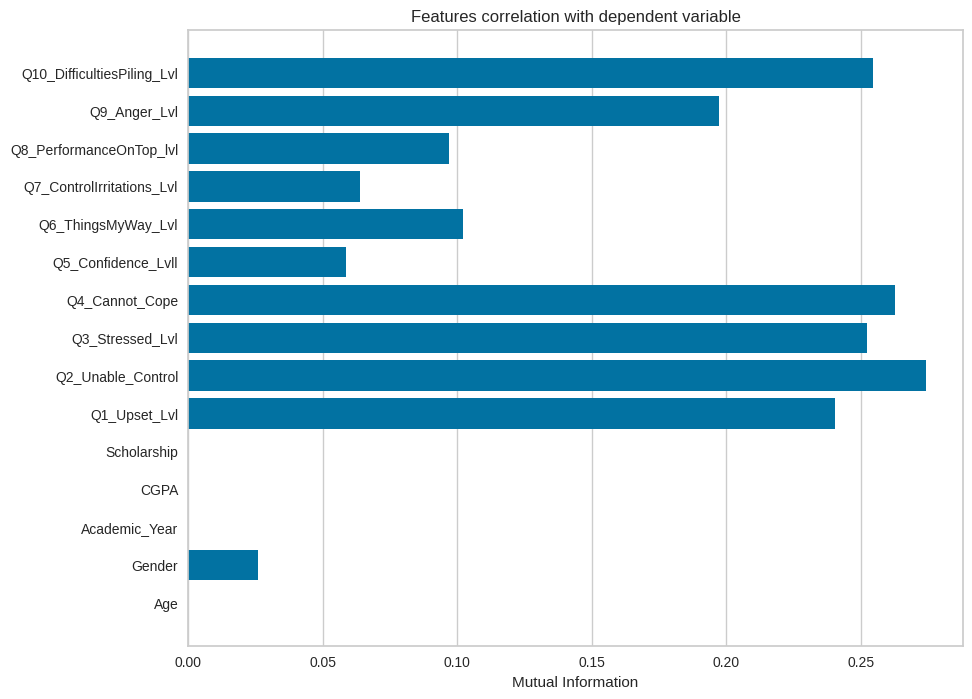

In [793]:
plt.figure(figsize=(10,8))
visualizer = feature_correlation(X_train_num, y_train, labels=list(X_train_num.columns),method='mutual_info-classification');

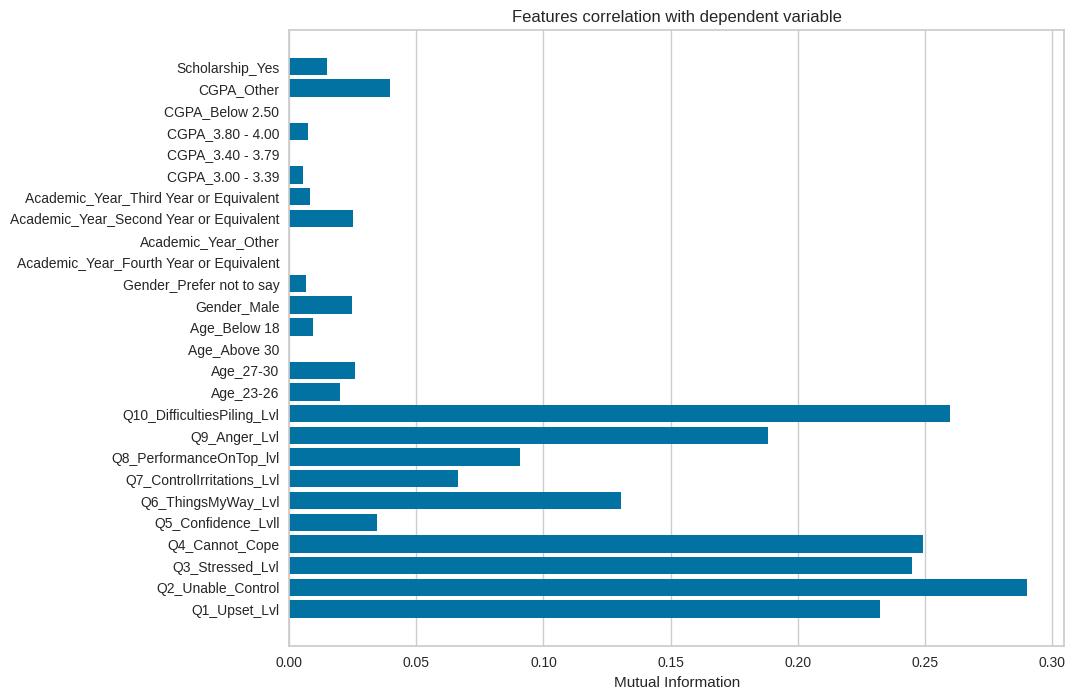

In [794]:
plt.figure(figsize=(10,8))
visualizer = feature_correlation(X_train_bin, y_train, labels=list(X_train_bin.columns),method='mutual_info-classification');

El análisis de Información Mutua, que evalúa tanto dependencias lineales como no lineales, confirma las conclusiones que hemos sacado del heatmap. Al igual que en la matriz de correlación, las preguntas psicológicas (Q1 a Q10) aportan con diferencia la mayor cantidad de información para predecir el estrés, destacando especialmente Q2, Q4 y Q10. Por el contrario, tanto en el conjunto numérico como en el binarizado, las variables demográficas (`Age`, `Gender`) y académicas (`CGPA`, `Scholarship`, `Academic_Year`) son características que no aportan ninguna información predictiva al problema.

TODO: Correlacion de pearson grafo

### Estandarización

Estandarizamos los conjuntos X (media 0, desviación 1) para que PCA y t-sne no den más peso a las variables solo por tener valores más grandes (en Y no se hace porque es la variable objetivo).

In [795]:
scaler = StandardScaler()

# Ajustamos y transformamos X_train y X_test del conjunto codificado numéricamente
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_num), columns=X_train_num.columns)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_num), columns=X_test_num.columns)

X_train_num_scaled.head()

,Age,Gender,Academic_Year,CGPA,Scholarship,Q1_Upset_Lvl,Q2_Unable_Control,Q3_Stressed_Lvl,Q4_Cannot_Cope,Q5_Confidence_Lvll,Q6_ThingsMyWay_Lvl,Q7_ControlIrritations_Lvl,Q8_PerformanceOnTop_lvl,Q9_Anger_Lvl,Q10_DifficultiesPiling_Lvl
0,-0.701,-1.479,-0.403,-0.375,-0.505,1.394,1.437,1.151,1.34,1.041,0.692,-0.080,1.491,1.345,1.340
1,-0.701,-1.479,0.421,1.208,-0.505,1.394,0.579,1.151,1.34,1.041,0.692,0.879,0.613,0.512,1.340
2,1.208,0.645,1.244,-0.375,-0.505,-0.301,-0.279,-0.614,-1.09,-0.778,-1.998,-0.080,-1.142,-0.321,-0.341
3,1.208,-1.479,1.244,-1.167,-0.505,1.394,1.437,1.151,1.34,-1.688,-1.998,-1.998,-2.020,1.345,1.340
4,-0.701,0.645,-1.227,2.000,-0.505,-0.301,-0.279,0.269,-0.28,0.132,-0.205,0.879,-0.265,-1.988,-1.182


In [796]:
X_train_num_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1383.0,-1.028e-16,1.0,-2.611,-0.701,-0.701,1.208,5.026
Gender,1383.0,1.105e-16,1.0,-1.479,-1.479,0.645,0.645,2.770
Academic_Year,1383.0,-3.083e-17,1.0,-1.227,-1.227,0.421,0.421,2.068
CGPA,1383.0,-1.137e-16,1.0,-1.958,-0.375,-0.375,0.417,2.000
Scholarship,1383.0,4.110e-17,1.0,-0.505,-0.505,-0.505,-0.505,1.980
Q1_Upset_Lvl,1383.0,-1.875e-16,1.0,-1.995,-0.301,-0.301,0.546,1.394
Q2_Unable_Control,1383.0,1.233e-16,1.0,-1.994,-0.279,-0.279,0.579,1.437
Q3_Stressed_Lvl,1383.0,6.422e-17,1.0,-2.379,-0.614,0.269,1.151,1.151
Q4_Cannot_Cope,1383.0,1.850e-16,1.0,-1.900,-0.280,-0.280,0.530,1.340
Q5_Confidence_Lvll,1383.0,-3.339e-17,1.0,-1.688,-0.778,0.132,0.132,1.951


In [797]:
# Ajustamos y transformamos X_train y X_test del conjunto binarizado
X_train_bin_scaled = pd.DataFrame(scaler.fit_transform(X_train_bin), columns=X_train_bin.columns)
X_test_bin_scaled = pd.DataFrame(scaler.transform(X_test_bin), columns=X_test_bin.columns)

X_train_bin_scaled.head()

,Q1_Upset_Lvl,Q2_Unable_Control,Q3_Stressed_Lvl,Q4_Cannot_Cope,Q5_Confidence_Lvll,Q6_ThingsMyWay_Lvl,Q7_ControlIrritations_Lvl,Q8_PerformanceOnTop_lvl,Q9_Anger_Lvl,Q10_DifficultiesPiling_Lvl,Age_23-26,Age_27-30,Age_Above 30,Age_Below 18,Gender_Male,Gender_Prefer not to say,Academic_Year_Fourth Year or Equivalent,Academic_Year_Other,Academic_Year_Second Year or Equivalent,Academic_Year_Third Year or Equivalent,CGPA_3.00 - 3.39,CGPA_3.40 - 3.79,CGPA_3.80 - 4.00,CGPA_Below 2.50,CGPA_Other,Scholarship_Yes
0,1.394,1.437,1.151,1.34,1.041,0.692,-0.080,1.491,1.345,1.340,-0.719,-0.108,-0.047,-0.054,-1.479,-0.071,-0.498,-0.198,2.103,-0.622,1.570,-0.623,-0.360,-0.205,-0.295,-0.505
1,1.394,0.579,1.151,1.34,1.041,0.692,0.879,0.613,0.512,1.340,-0.719,-0.108,-0.047,-0.054,-1.479,-0.071,-0.498,-0.198,-0.475,1.607,-0.637,-0.623,2.775,-0.205,-0.295,-0.505
2,-0.301,-0.279,-0.614,-1.09,-0.778,-1.998,-0.080,-1.142,-0.321,-0.341,1.392,-0.108,-0.047,-0.054,0.676,-0.071,2.007,-0.198,-0.475,-0.622,1.570,-0.623,-0.360,-0.205,-0.295,-0.505
3,1.394,1.437,1.151,1.34,-1.688,-1.998,-1.998,-2.020,1.345,1.340,1.392,-0.108,-0.047,-0.054,-1.479,-0.071,2.007,-0.198,-0.475,-0.622,-0.637,-0.623,-0.360,-0.205,-0.295,-0.505
4,-0.301,-0.279,0.269,-0.28,0.132,-0.205,0.879,-0.265,-1.988,-1.182,-0.719,-0.108,-0.047,-0.054,0.676,-0.071,-0.498,-0.198,-0.475,-0.622,-0.637,-0.623,-0.360,-0.205,3.385,-0.505


In [798]:
X_train_bin_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
Q1_Upset_Lvl,1383.0,-1.875e-16,1.0,-1.995,-0.301,-0.301,0.546,1.394
Q2_Unable_Control,1383.0,1.233e-16,1.0,-1.994,-0.279,-0.279,0.579,1.437
Q3_Stressed_Lvl,1383.0,6.422e-17,1.0,-2.379,-0.614,0.269,1.151,1.151
Q4_Cannot_Cope,1383.0,1.850e-16,1.0,-1.900,-0.280,-0.280,0.530,1.340
Q5_Confidence_Lvll,1383.0,-3.339e-17,1.0,-1.688,-0.778,0.132,0.132,1.951
Q6_ThingsMyWay_Lvl,1383.0,-7.193e-17,1.0,-1.998,-0.205,-0.205,0.692,1.589
Q7_ControlIrritations_Lvl,1383.0,5.138e-18,1.0,-1.998,-0.080,-0.080,0.879,1.838
Q8_PerformanceOnTop_lvl,1383.0,3.596e-17,1.0,-2.020,-0.265,-0.265,0.613,1.491
Q9_Anger_Lvl,1383.0,-9.248e-17,1.0,-1.988,-0.321,-0.321,0.512,1.345
Q10_DifficultiesPiling_Lvl,1383.0,1.053e-16,1.0,-2.022,-0.341,-0.341,0.500,1.340


Con los describes podemos ver que la estandarización en ambos conjuntos se ha hecho correctamente y que todas las variables poseen ahora el mismo rango en su respectivo conjunto. Esto también es visible porque la media (mean) es cero (prácticamente 0) y la desviación estándar (std) es exactamente 1.0 en todas las características.

### PCA

Una vez los conjuntos están estandarizados, pasamos a aplicar el PCA en ambos conjuntos. Esto nos permitirá ver cómo se distribuye la varianza explicada y si los niveles de estrés forman agrupaciones claras en menor dimensión.


Varianza acumulada (Numérico): [0.26547599 0.42286182 0.53707575 0.60846133 0.67123934 0.72578345
 0.76698436 0.80668102 0.84340755 0.87546502 0.90486923 0.93341467
 0.95689603 0.97861299 1.        ]
Varianza acumulada (Binarizado): [0.15455154 0.24872927 0.31681268 0.37094184 0.42290351 0.47116506
 0.51575873 0.55865208 0.60127526 0.64130494 0.68059491 0.7181729
 0.75400683 0.78852812 0.81933016 0.84325005 0.86645337 0.88886891
 0.90942353 0.92782676 0.94467972 0.95818294 0.97057226 0.98277649
 0.99206989 1.        ]


Text(0, 0.5, 'Variancia explicada')

Text(0.5, 0, 'Componentes')

Text(0.5, 1.0, 'PCA - Conjunto Numérico')

Text(0, 0.5, 'Variancia explicada')

Text(0.5, 0, 'Componentes')

Text(0.5, 1.0, 'PCA - Conjunto Binarizado')

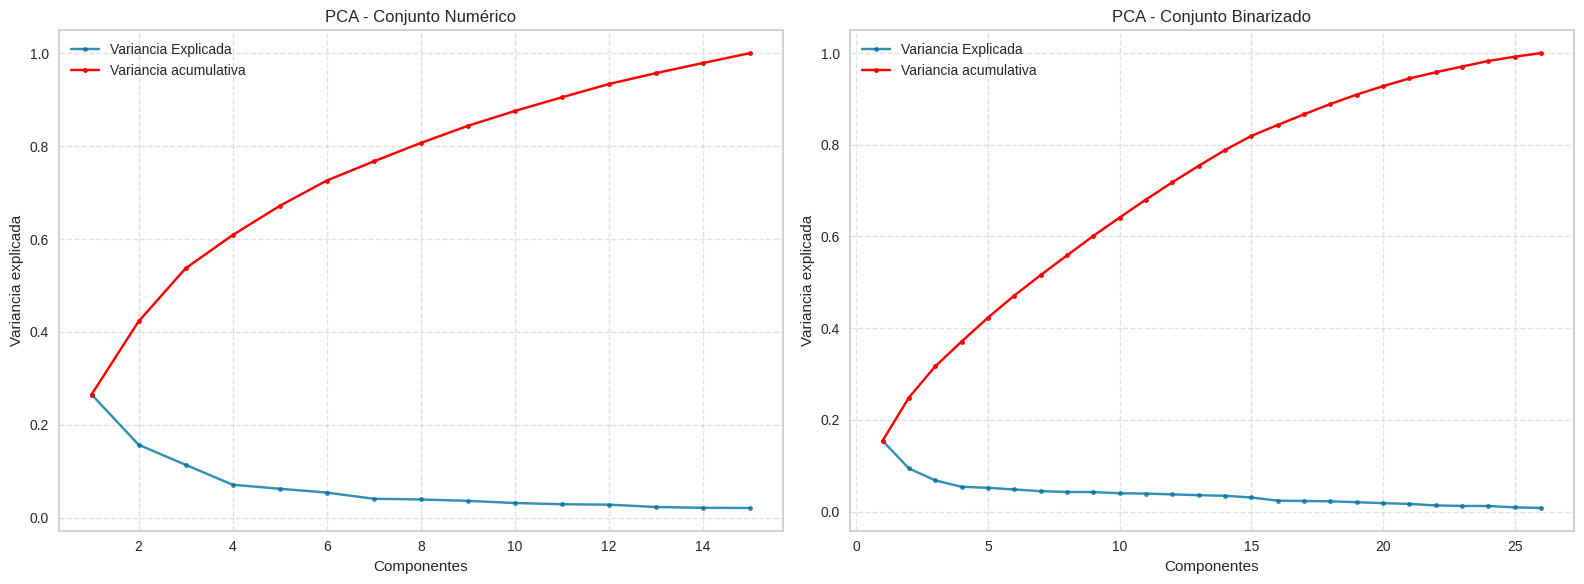

In [799]:
# Aplicar PCA a los 2 conjuntos
pca_num = PCA().fit(X_train_num_scaled)
pca_bin = PCA().fit(X_train_bin_scaled)

print("Varianza acumulada (Numérico):", pca_num.explained_variance_ratio_.cumsum())
print("Varianza acumulada (Binarizado):", pca_bin.explained_variance_ratio_.cumsum())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfica 1 (conj. numerizado)
axes[0].plot(range(1, len(pca_num.explained_variance_ratio_) + 1), 
             pca_num.explained_variance_ratio_, alpha=0.8, marker='.', label="Variancia Explicada")
axes[0].plot(range(1, len(pca_num.explained_variance_ratio_) + 1),
             np.cumsum(pca_num.explained_variance_ratio_), c='red', marker='.', label="Variancia acumulativa")
axes[0].set_ylabel('Variancia explicada')
axes[0].set_xlabel('Componentes')
axes[0].set_title('PCA - Conjunto Numérico')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Gráfica 2 (conj. binarizado)
axes[1].plot(range(1, len(pca_bin.explained_variance_ratio_) + 1), 
             pca_bin.explained_variance_ratio_, alpha=0.8, marker='.', label="Variancia Explicada")
axes[1].plot(range(1, len(pca_bin.explained_variance_ratio_) + 1),
             np.cumsum(pca_bin.explained_variance_ratio_), c='red', marker='.', label="Variancia acumulativa")
axes[1].set_ylabel('Variancia explicada')
axes[1].set_xlabel('Componentes')
axes[1].set_title('PCA - Conjunto Binarizado')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

# Ajustar el espaciado y mostrar
plt.tight_layout()
plt.show()

Como se puede observar, la información de los conjuntos está bastante distribuida y no depende de un único factor, ya que se puede ver claramente que el primer componente (PC1) en ambos conjuntos explica solo alrededor de un 20% de la varianza original. Además, aunque la curva de varianza acumulada crece de forma gradual, el modelo necesita agrupar **8** componentes para el conjunto numérico y **14** para el conjunto binarizado, con tal de llegar a retener almenos un 80% de la información original.

Para entender cómo influyen las variables originales a la formación de los nuevos componentes, podemos hacer un heatmap para ver las relaciones en ambos conjuntos. 

<Axes: >

Text(0.5, 1.0, 'Conjunto Numérico')

<Axes: >

Text(0.5, 1.0, 'Conjunto Binarizado')

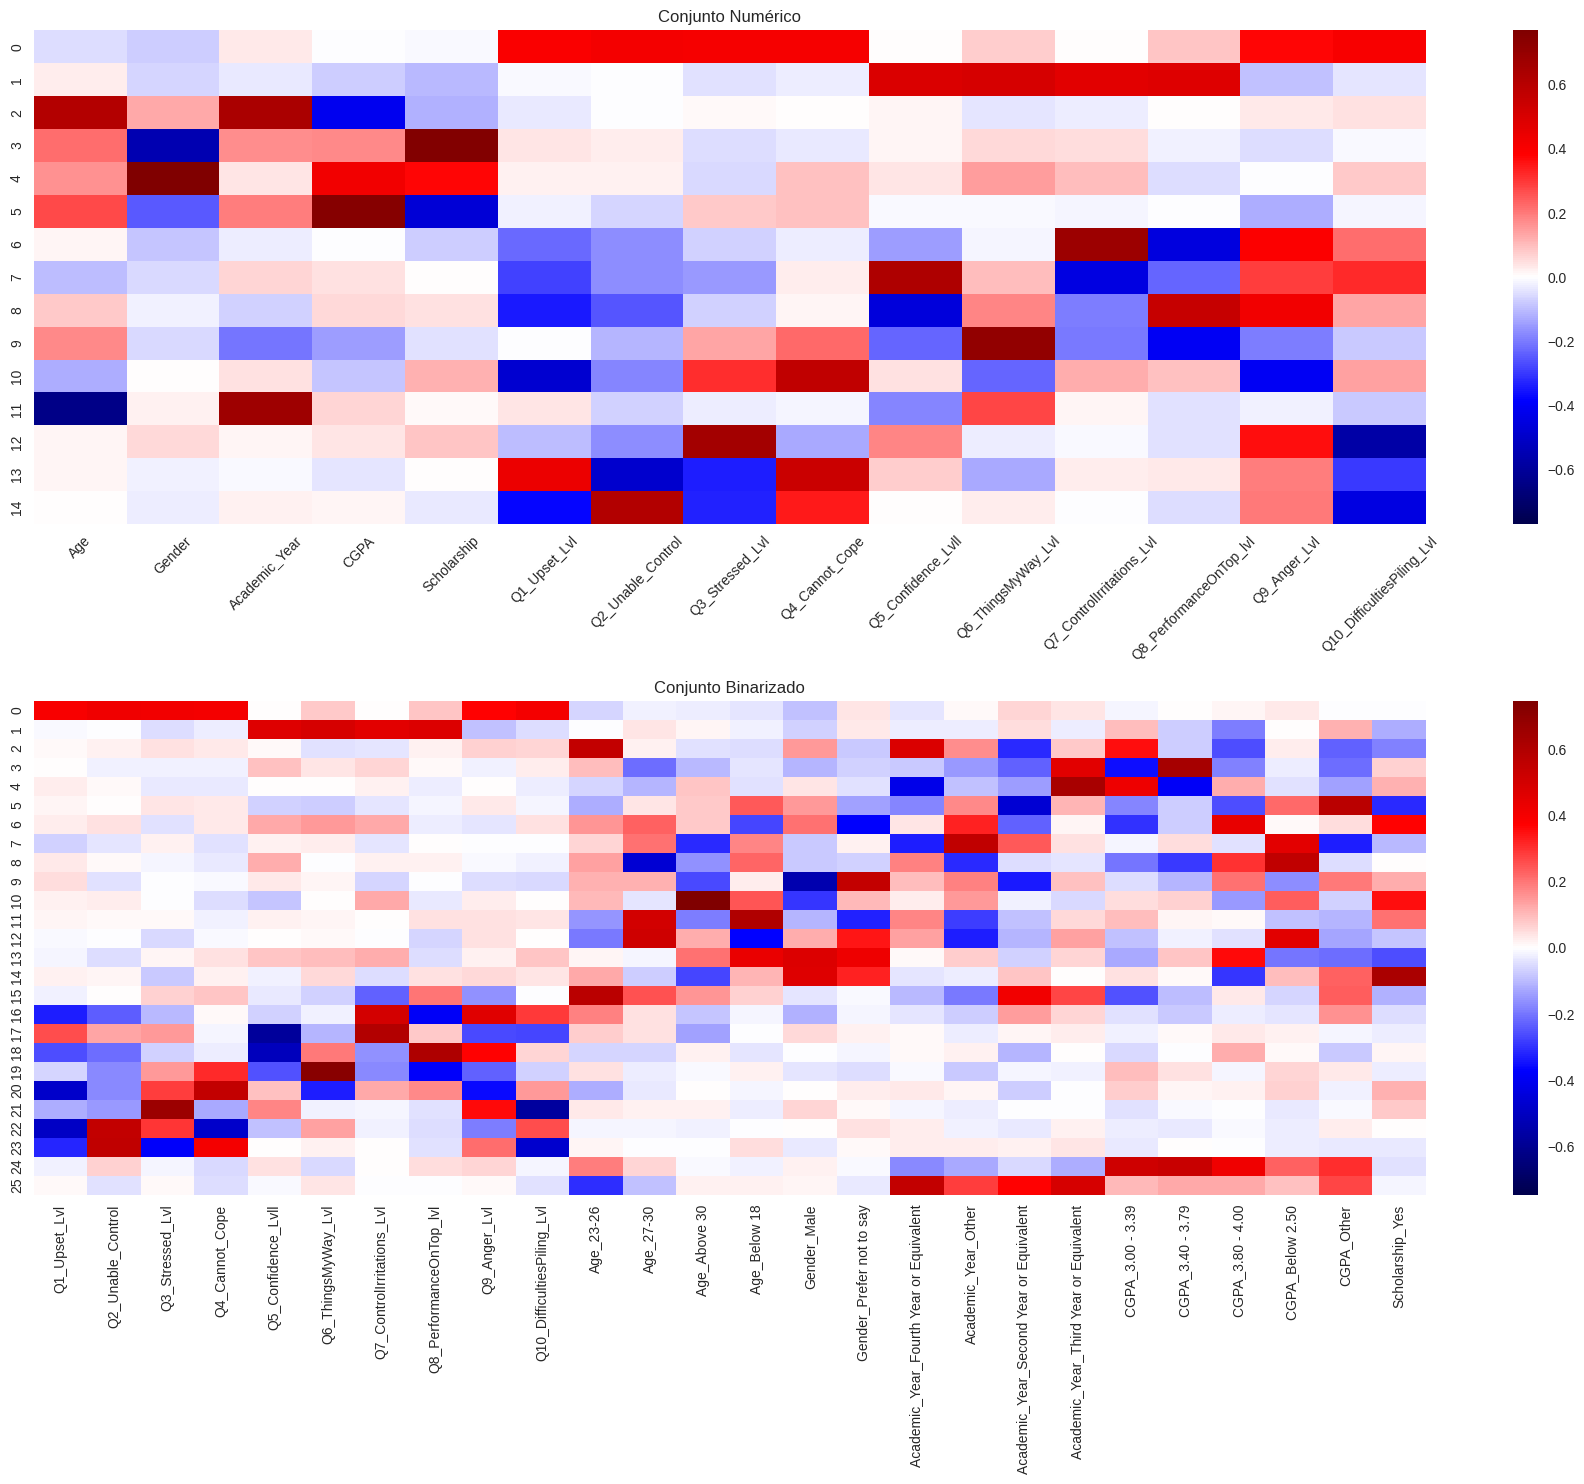

In [800]:
fig, axes = plt.subplots(2, 1, figsize=(18, 15))

# Heatmap del conjunto numérico
vmax_num = np.max(np.abs(pca_num.components_))
sns.heatmap(pca_num.components_, cmap='seismic', 
            xticklabels=list(X_train_num_scaled.columns),
            vmin=-vmax_num, vmax=vmax_num, annot=False, ax=axes[0])
axes[0].set_title('Conjunto Numérico')
axes[0].tick_params(axis='x', rotation=45)

# Heatmap del conjunto binarizado
vmax_bin = np.max(np.abs(pca_bin.components_))
sns.heatmap(pca_bin.components_, cmap='seismic', 
            xticklabels=list(X_train_bin_scaled.columns),
            vmin=-vmax_bin, vmax=vmax_bin, annot=False, ax=axes[1])
axes[1].set_title('Conjunto Binarizado')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

Explicar

A continuación, para ver la distribución de la variable objetivo en cada conjunto, transformamos los datos usando los PCAs entrenados, nos quedamos con los dos primeros componentes (PC1 y PC2), y los graficamos usando la variable objetivo como escala de color.

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA 2D - Distribución del estrés (numérico)')

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA 2D - Distribución del estrés (binarizado)')

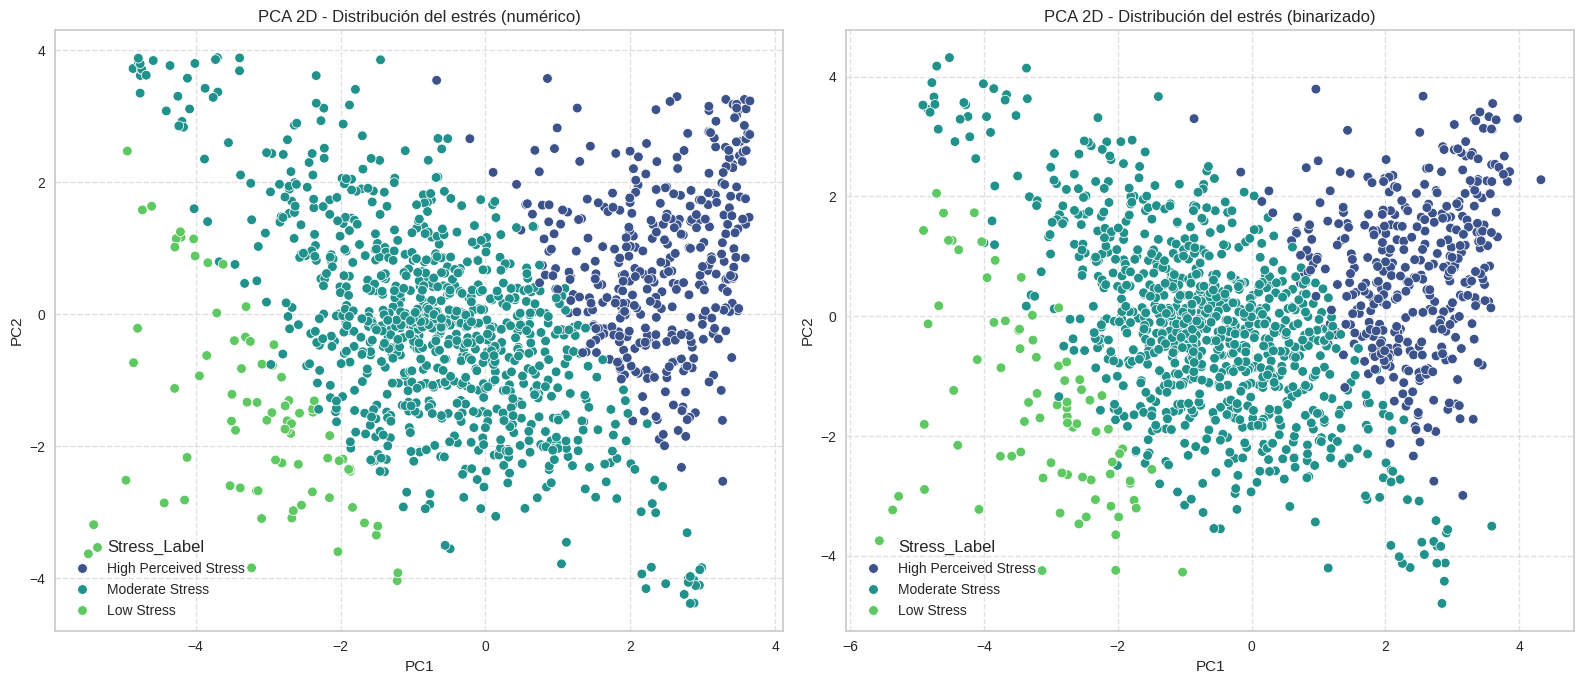

In [801]:
transformed_stress_num = pca_num.transform(X_train_num_scaled)
transformed_stress_bin = pca_bin.transform(X_train_bin_scaled)

df_plot_num = X_train_num_scaled.copy()
df_plot_num['PC1'] = transformed_stress_num[:, 0]
df_plot_num['PC2'] = transformed_stress_num[:, 1]
df_plot_num['Stress_Label'] = y_train.values

df_plot_bin = X_train_bin_scaled.copy()
df_plot_bin['PC1'] = transformed_stress_bin[:, 0]
df_plot_bin['PC2'] = transformed_stress_bin[:, 1]
df_plot_bin['Stress_Label'] = y_train.values

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Gráfica de conjunto numérico
sns.scatterplot(x='PC1', y='PC2', hue='Stress_Label', data=df_plot_num, palette='viridis', ax=axes[0])
axes[0].set_title('PCA 2D - Distribución del estrés (numérico)')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Gráfica de conjunto binarizado
sns.scatterplot(x='PC1', y='PC2', hue='Stress_Label', data=df_plot_bin, palette='viridis', ax=axes[1])
axes[1].set_title('PCA 2D - Distribución del estrés (binarizado)')
axes[1].grid(True, linestyle='--', alpha=0.6)

# Ajustar diseño y mostrar
plt.tight_layout()
plt.show()

A partir de los dos gráficos podemos ver que hay relación entre los componentes y la variable objetivo. Los puntos forman una separación clara entre cada nivel de estrés. Se puede ver con claridad que la etiqueta del estrés (`Stress_Label`), empeora gradualmente a medida que nos movemos hacia la derecha, formando un gradiente a medida que avanzamos por el eje PC1.

Al obtener resultados muy parecidos en ambos conjuntos, todavía no se puede decidir que conjunto es mejor (si el numérico o el binarizado).

Para entender qué separa las dos ramas del gráfico PCA, calcularemos la correlación de cada variable con el estrés del estudiante (`Stress_Label`). Así identificaremos las características que más influyen (positiva y negativamente) y las usaremos para colorear el gráfico, comprobando si estas variables son las que realmente organizan los datos.

Al obtener antes resultados casi idénticos en las gráficas de las proyecciones PCA, solo es necesario hacerlo con uno de los dos conjuntos. Se escoge el numérico porque además de necesitar menos componentes y ser menos complejo, se podrá ver el impacto de cada pregunta o atributo sin que se divida en variables más pequeñas al haber hecho One-Hot Encoding. En el conjunto binarizado, la información se fragmentaría en múltiples variables (Q1_Upset_Lvl_1, Q1_Upset_Lvl_2, etc.), lo que dificultaría la obtención de conclusiones.

<Axes: title={'center': 'Correlación de cada variable con la variable objetivo'}>

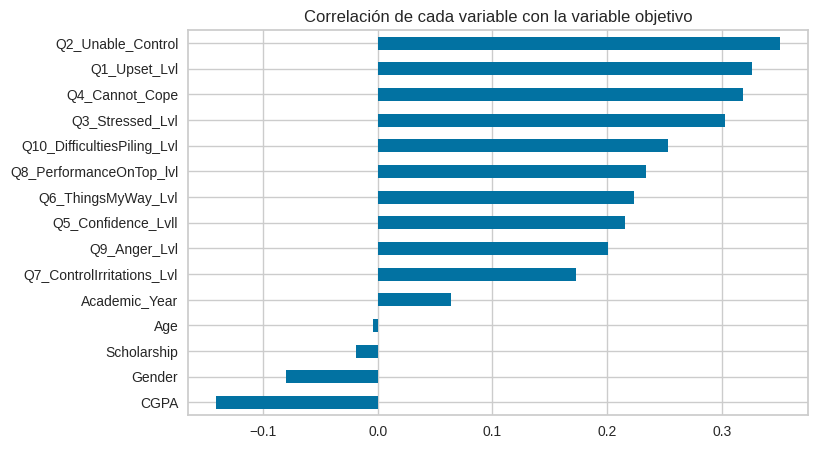

In [802]:
corr_target = X_train_num_scaled.corrwith(y_train_num.reset_index(drop=True)).sort_values()
corr_target.plot.barh(figsize=(8,5), title="Correlación de cada variable con la variable objetivo")
plt.show()

Las cuatro primeras preguntas (`Q1`, `Q2`, `Q3` y `Q4`) tienen la mayor correlación positiva con el estrés del estudiante, mientras que el `CGPA` y el `Gender` tienen la mayor correlación negativa.

A continuación, volvemos a dibujar el gráfico PCA en una cuadrícula de 6 gráficos, coloreando los puntos según estas variables clave para ver cómo estructuran el modelo internamente, y ver si se puede ver algún patrón claro que justifique la separación de las etiquetas de estrés en los gráficos de distribución anteriores.

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Q2_Unable_Control')

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Q1_Upset_Lvl')

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Q4_Cannot_Cope')

... (2 outputs left out)

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - CGPA')

<Axes: xlabel='PC1', ylabel='PC2'>

Text(0.5, 1.0, 'PCA - Gender')

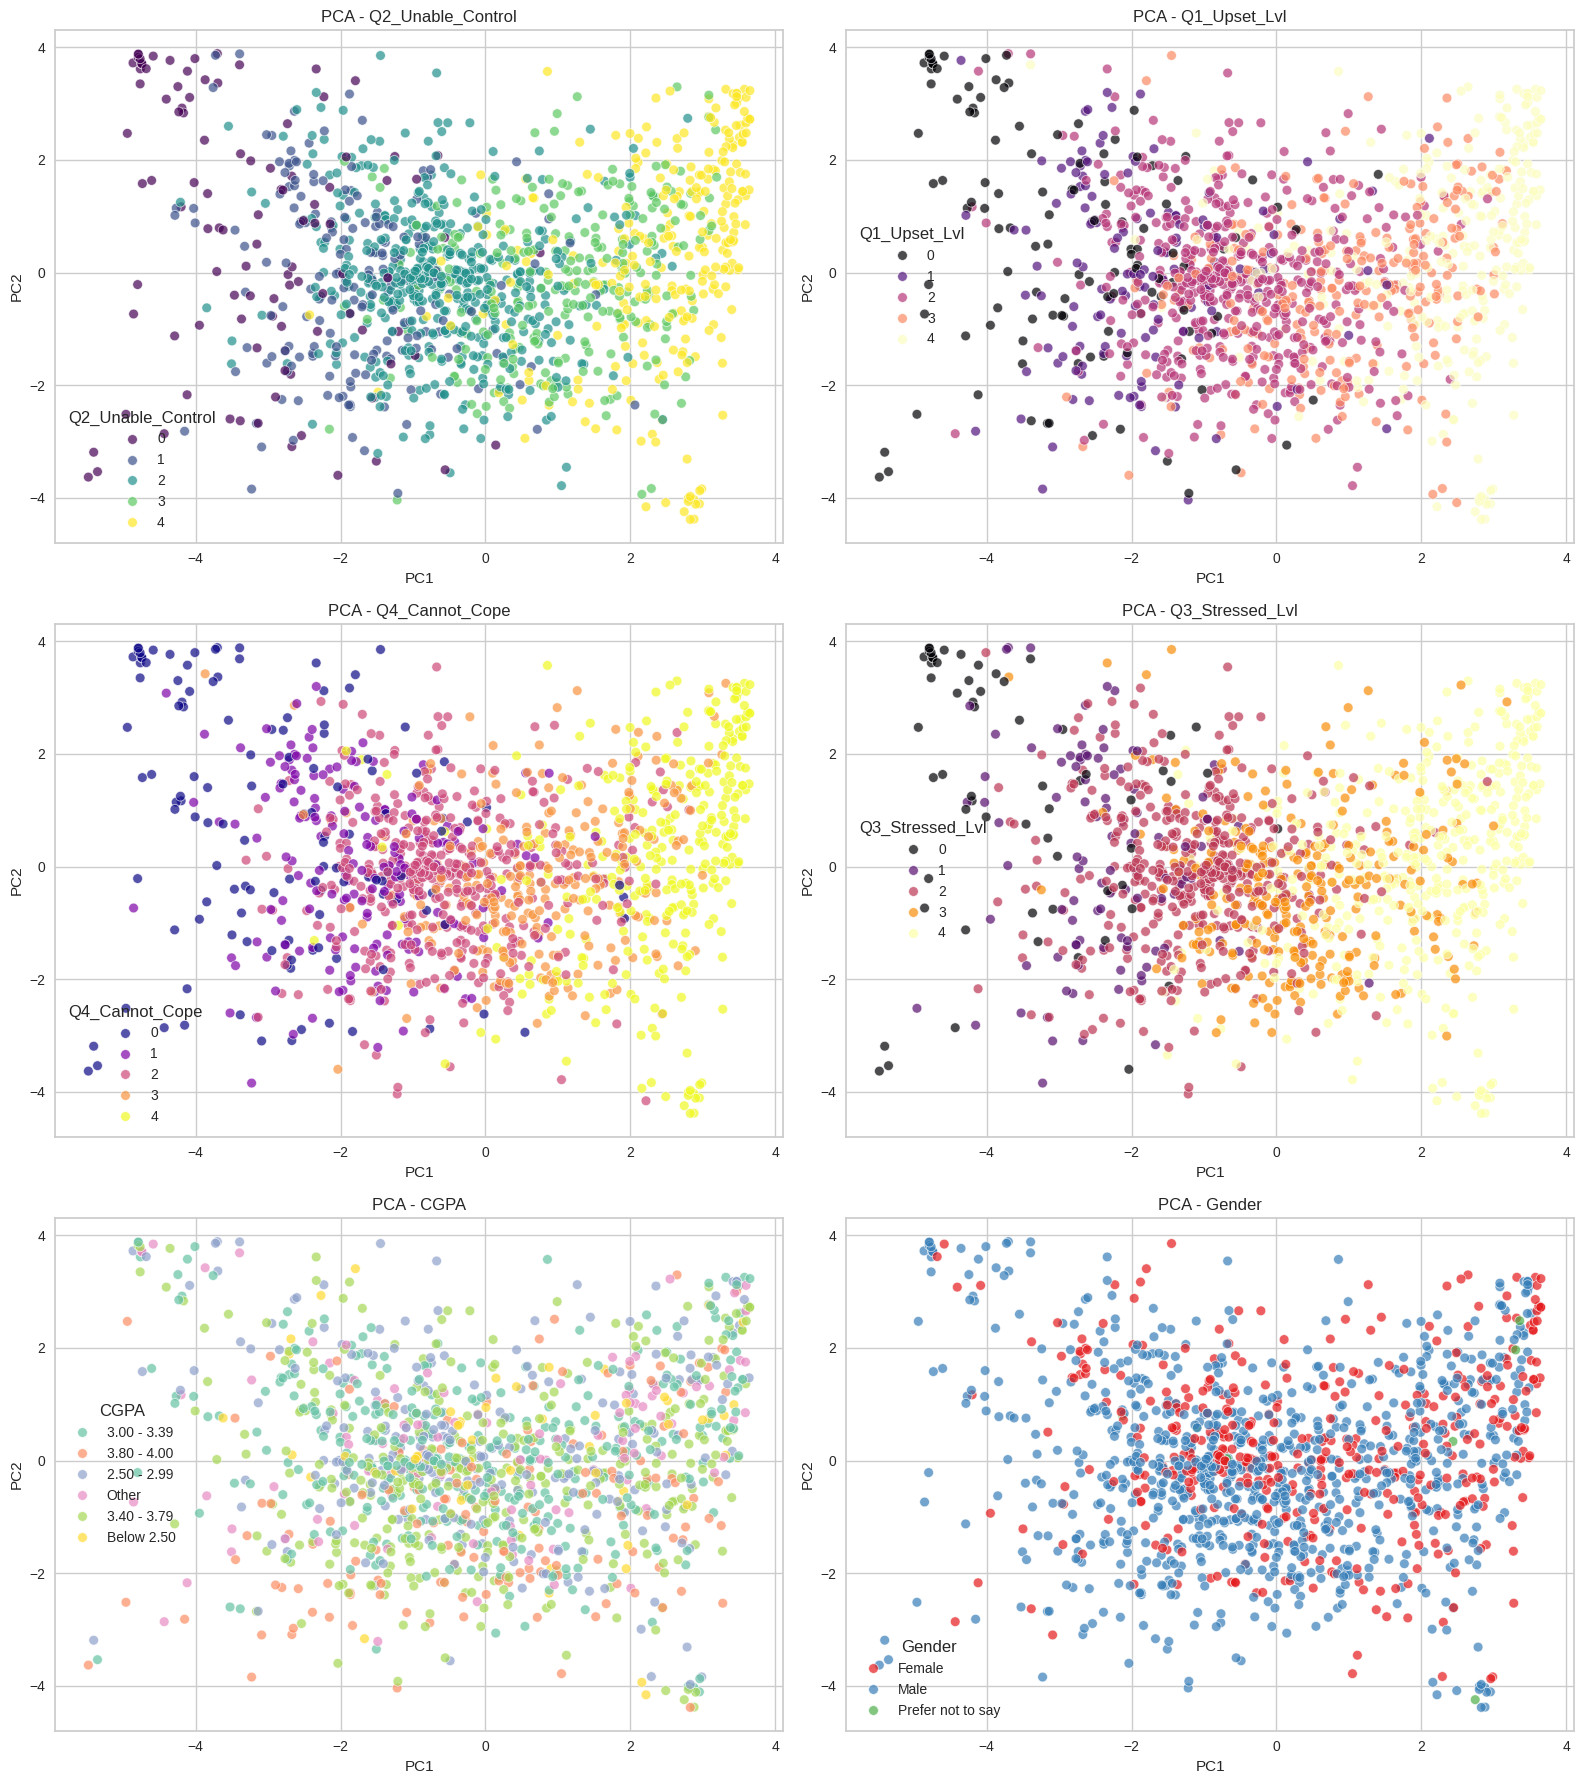

In [803]:
df_pca = pd.DataFrame({
    'PC1': transformed_stress_num[:, 0],
    'PC2': transformed_stress_num[:, 1]
})

# Añadimos las 6 variables mencionadas
df_pca['Q2_Unable_Control'] = X_train['Q2_Unable_Control'].values
df_pca['Q1_Upset_Lvl'] = X_train['Q1_Upset_Lvl'].values
df_pca['Q4_Cannot_Cope'] = X_train['Q4_Cannot_Cope'].values
df_pca['Q3_Stressed_Lvl'] = X_train['Q3_Stressed_Lvl'].values
df_pca['CGPA'] = X_train['CGPA'].values
df_pca['Gender'] = X_train['Gender'].values

# Cuadrícula de gráficos de 3x2
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Q2_Unable_Control (Mayor correlación positiva)
sns.scatterplot(x='PC1', y='PC2', hue='Q2_Unable_Control', data=df_pca, ax=axes[0, 0], palette='viridis', alpha=0.7)
axes[0, 0].set_title('PCA - Q2_Unable_Control')

# 2. Q1_Upset_Lvl
sns.scatterplot(x='PC1', y='PC2', hue='Q1_Upset_Lvl', data=df_pca, ax=axes[0, 1], palette='magma', alpha=0.7)
axes[0, 1].set_title('PCA - Q1_Upset_Lvl')

# 3. Q4_Cannot_Cope
sns.scatterplot(x='PC1', y='PC2', hue='Q4_Cannot_Cope', data=df_pca, ax=axes[1, 0], palette='plasma', alpha=0.7)
axes[1, 0].set_title('PCA - Q4_Cannot_Cope')

# 4. Q3_Stressed_Lvl
sns.scatterplot(x='PC1', y='PC2', hue='Q3_Stressed_Lvl', data=df_pca, ax=axes[1, 1], palette='inferno', alpha=0.7)
axes[1, 1].set_title('PCA - Q3_Stressed_Lvl')

# 5. CGPA
# Usamos una paleta categórica porque son rangos de texto
sns.scatterplot(x='PC1', y='PC2', hue='CGPA', data=df_pca, ax=axes[2, 0], palette='Set2', alpha=0.7)
axes[2, 0].set_title('PCA - CGPA')

# 6. Gender
sns.scatterplot(x='PC1', y='PC2', hue='Gender', data=df_pca, ax=axes[2, 1], palette='Set1', alpha=0.7)
axes[2, 1].set_title('PCA - Gender')

plt.tight_layout()
plt.show()

A partir de las gráficas generadas en la imagen, podemos extraer varias conclusiones claras sobre como se estructura el modelo internamente. En los cuatro primeros gráficos correspondientes a las variables que tenían correlación positiva, podemos ver que los colores puntos de colores se separan con claridad. Esto nos indica que los estudiantes que respondieron con valores más bajos a estas 4 preguntas (colores oscuros), se agrupan en la parte izquierda, mientras que aquellos con respuestas de valores altos (colores más claros), se concentran en la parte derecha del plano. Por tanto, se puede decir que los estudiantes con menos decepcionados (`Q1`), estresados (`Q3`), y con más capacidad de afrontar problemas (`Q4`) y tener control (`Q2`) son los que tienen la etiqueta de `Low_Stress`, algo que tiene todo el sentido del mundo.

Por el contrario, en lo referente a las dos variables que tenían más correlación negativa con la variable objetivo, no se puede decir gran cosa, ya que todos los puntos y colores están mezclados y no hay patrones o gradientes claros a extraer. Por tanto, no existe una separación evidente basada en las características demográficas (`Gender`) y/o académicas (`CGPA`).

En conclusión, la distribución de los estudiantes en el modelo PCA depende casi por completo de la actitud psicológica y la capacidad de afrontar los problemas, dejando de lado factores como el género o las notas.

### T-SNE
Para acabar el primer apartado del problema, haremos para cada conjunto su respectivo t-sne. 

<Axes: >

Text(0.5, 1.0, 't-SNE - Conjunto Numérico')

<Axes: >

Text(0.5, 1.0, 't-SNE - Conjunto Binarizado')

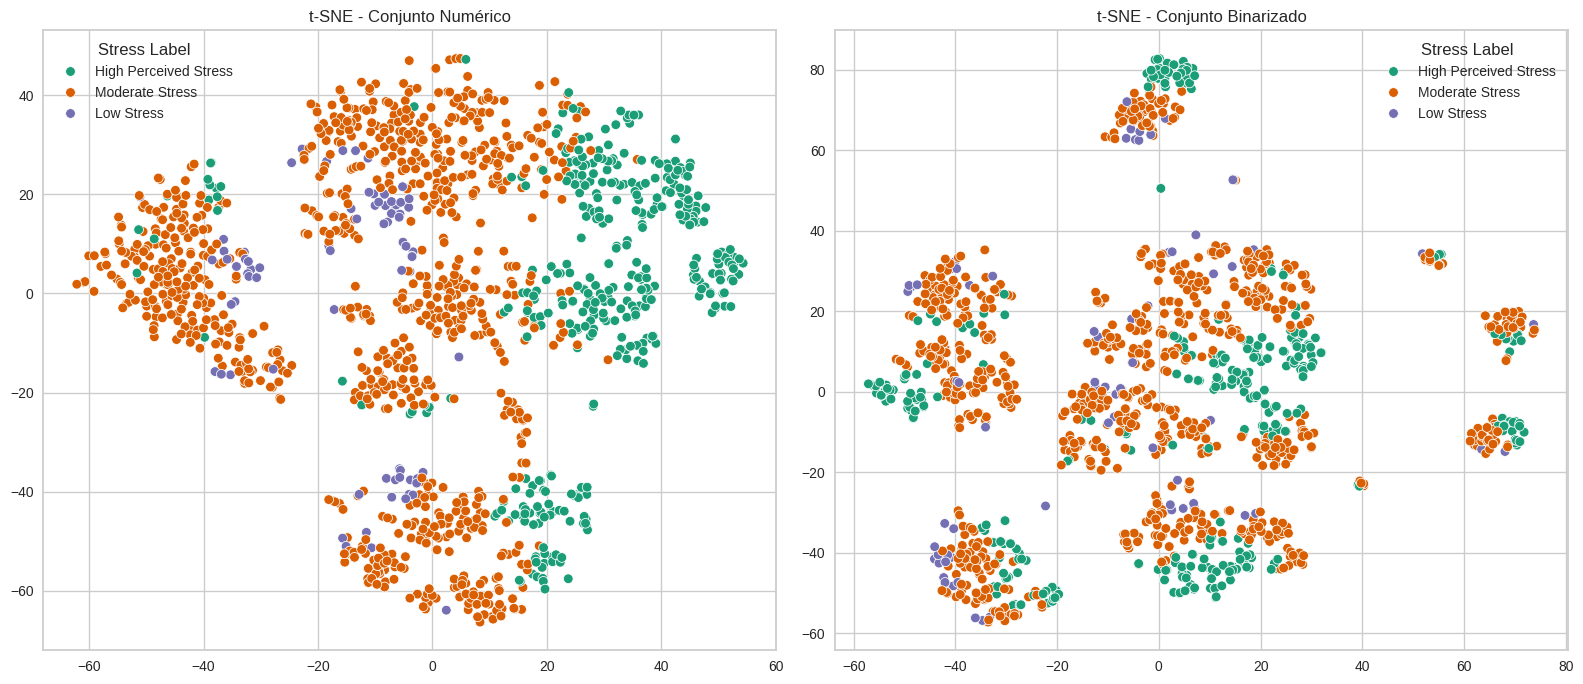

In [804]:
X_trans_num = TSNE(n_components=2, perplexity=20, max_iter=2000, init='pca', random_state=42).fit_transform(X_train_num_scaled)
X_trans_bin = TSNE(n_components=2, perplexity=20, max_iter=2000, init='pca', random_state=42).fit_transform(X_train_bin_scaled)


fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Conjunto numérico
sns.scatterplot(x=X_trans_num[:, 0], y=X_trans_num[:, 1], hue=y_train, palette='Dark2', ax=axes[0])
axes[0].set_title('t-SNE - Conjunto Numérico')

# Conjunto binarizado
sns.scatterplot(x=X_trans_bin[:, 0], y=X_trans_bin[:, 1], hue=y_train, palette='Dark2', ax=axes[1])
axes[1].set_title('t-SNE - Conjunto Binarizado')

plt.tight_layout()
plt.show()


TODO: if correct, explicar conclusiones

## APARTADO B

### LDA
TODO: mejorar intro apartado b

Para empezar este apartado, probaremos a clasificar usando el discriminante lineal sobre los datos de entrenamiento en ambos conjuntos.

Primero procedemos a obtener el error de validación cruzada con los datos de entrenamiento:

In [805]:
lda = LinearDiscriminantAnalysis()
lda.best_score_ = np.mean(cross_val_score(lda,X_train_num_scaled,y_train,cv=10))
print(lda.best_score_)

0.9681680742362632


In [806]:
lda = LinearDiscriminantAnalysis()
lda.best_score_ = np.mean(cross_val_score(lda,X_train_bin_scaled,y_train,cv=10))
print(lda.best_score_)

0.9645761651548328


El acierto del modelo es bastante bueno y prácticamente idéntico en ambos modelos. En este caso no tenemos ningún hiper parámetro que ajustar asi que podemos ajustar el modelo con todos los datos del conjunto de entrenamiento para ver que modelo obtenemos y después podemos comprobar como lo hace con el conjunto de test

Priors: [0.27621114 0.05784526 0.6659436 ]
Means:

Intercepts:
Explained Variance Ratio
Coefs:
Priors: [0.27621114 0.05784526 0.6659436 ]
Means:

Intercepts:
Explained Variance Ratio
Coefs:


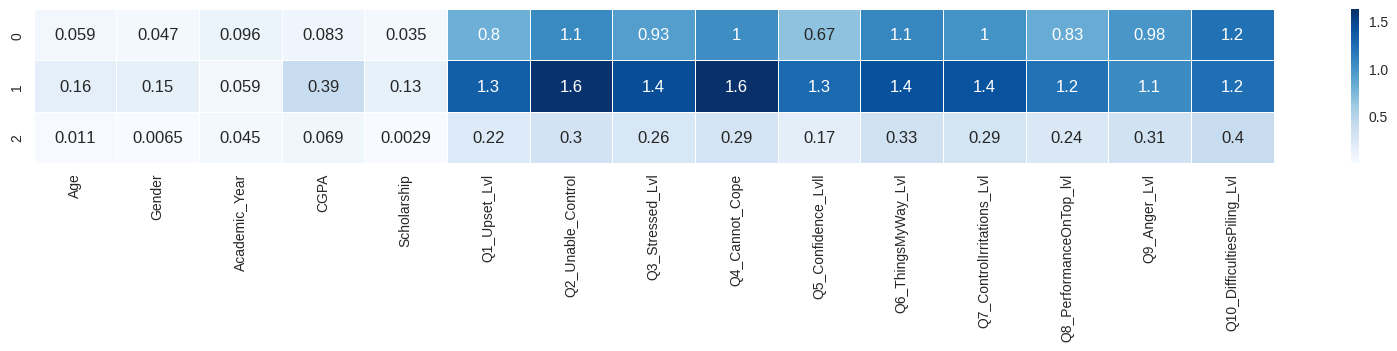

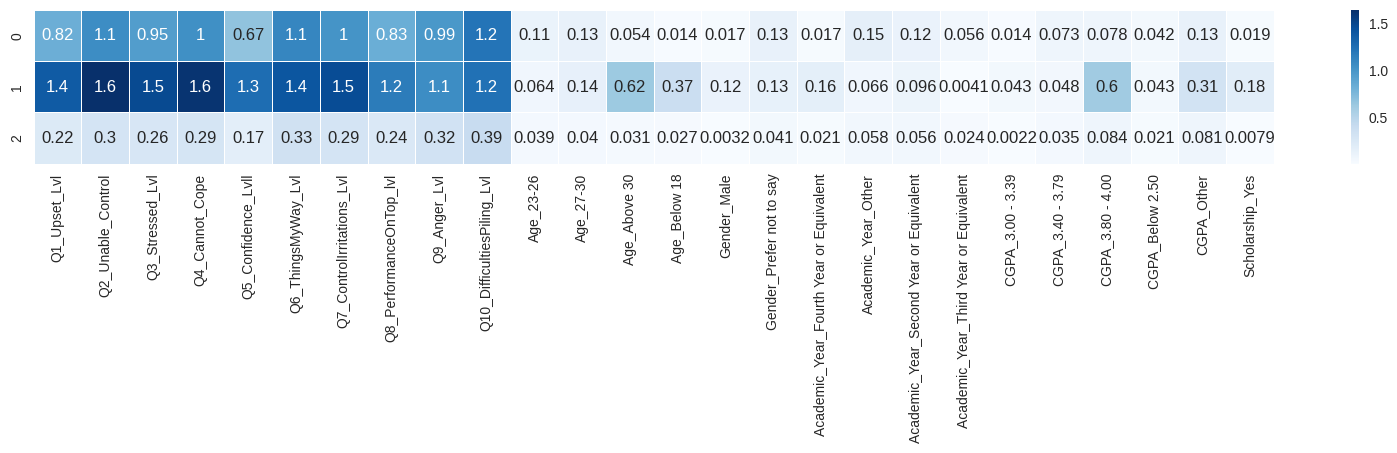

In [807]:
# Conjunto numérico
lda_model_num = LinearDiscriminantAnalysis().fit(X_train_num_scaled, y_train)

print('Priors:', lda_model_num.priors_)
print('Means:\n')
means_num =pd.DataFrame(lda_model_num.means_)
means_num.columns=X_train_num_scaled.columns
means_num

print('Intercepts:')
intercepts_num = pd.DataFrame(lda_model_num.intercept_)
intercepts_num

print('Explained Variance Ratio')
pd.DataFrame(lda_model_num.explained_variance_ratio_ )

print('Coefs:')
coefs_num = pd.DataFrame(lda_model_num.coef_)
coefs_num.columns = X_train_num_scaled.columns

plt.figure(figsize=(20,2));
sns.heatmap(coefs_num.abs(),annot=True, linewidths=.5,cbar=True,xticklabels=True, cmap='Blues', annot_kws={'size':12});


# Conjunto binarizado
lda_model_bin = LinearDiscriminantAnalysis().fit(X_train_bin_scaled, y_train)
print('Priors:', lda_model_bin.priors_)
print('Means:\n')
means_bin =pd.DataFrame(lda_model_bin.means_)
means_bin.columns= X_train_bin_scaled.columns
means_bin

print('Intercepts:')
intercepts_bin = pd.DataFrame(lda_model_bin.intercept_)
intercepts_bin

print('Explained Variance Ratio')
pd.DataFrame(lda_model_bin.explained_variance_ratio_ )

print('Coefs:')
coefs_bin = pd.DataFrame(lda_model_bin.coef_)
coefs_bin.columns = X_train_bin_scaled.columns

plt.figure(figsize=(20,2));
sns.heatmap(coefs_bin.abs(),annot=True, linewidths=.5,cbar=True,xticklabels=True, cmap='Blues', annot_kws={'size':12});


TODO: explicar (Podemos ver en el modelo cuales son los atributos más importantes.)....

Para saber la calidad del modelo podemos aplicarlo a los datos de test. El _classification report_ nos dara todas las medidas que necesitamos para tomar decisiones (aunque en este caso no hay ninguna)

In [808]:
# Conjunto numérico
lda_model_num.best_score_ = lda.best_score_
print(classification_report(y_test, lda_model_num.predict(X_test_num_scaled), target_names=['Low Stress', 'Moderate Stress', 'High Perceived Stress']))
results_df = save_results(lda_model_num, X_test_num_scaled, y_test, 'LDA', results_df)

print("------------------------------------------------------------------")

# Conjunto binarizado
lda_model_bin.best_score_ = lda.best_score_
print(classification_report(y_test, lda_model_bin.predict(X_test_bin_scaled), target_names=['Low Stress', 'Moderate Stress', 'High Perceived Stress']))
results_df = save_results(lda_model_bin, X_test_bin_scaled, y_test, 'LDA', results_df)

                       precision    recall  f1-score   support

           Low Stress       0.99      0.95      0.97       164
      Moderate Stress       0.94      0.86      0.90        35
High Perceived Stress       0.97      0.99      0.98       395

             accuracy                           0.97       594
            macro avg       0.97      0.93      0.95       594
         weighted avg       0.97      0.97      0.97       594

------------------------------------------------------------------
                       precision    recall  f1-score   support

           Low Stress       0.99      0.96      0.97       164
      Moderate Stress       0.89      0.69      0.77        35
High Perceived Stress       0.96      0.99      0.97       395

             accuracy                           0.96       594
            macro avg       0.94      0.88      0.91       594
         weighted avg       0.96      0.96      0.96       594



TODO: explicar

Podemos ver también en la matriz de confusión que errores se cometen en cada conjunto.

Text(0.5, 1.0, 'LDA - Conjunto Numérico')

Text(0.5, 1.0, 'LDA - Conjunto Binarizado')

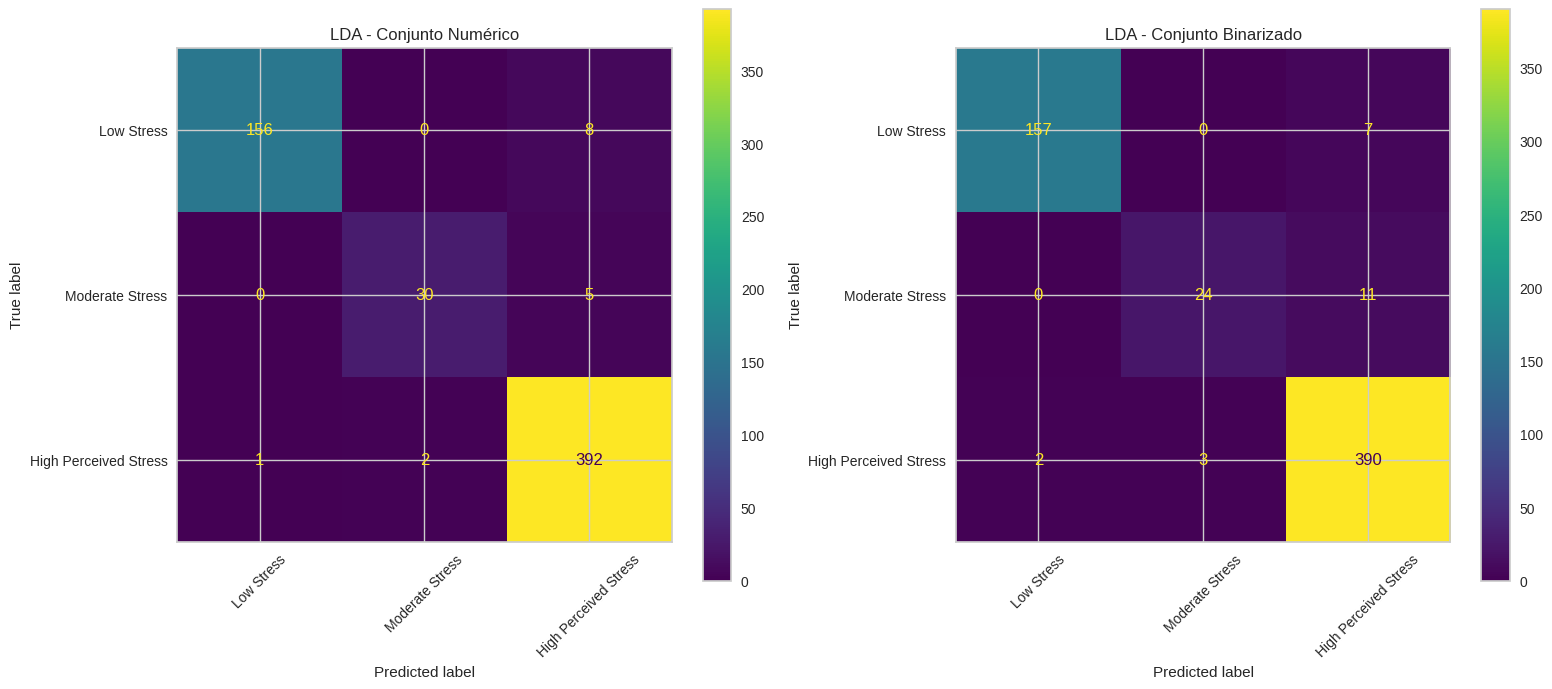

In [809]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Conjunto numérico
ConfusionMatrixDisplay.from_estimator(lda_model_num, X_test_num_scaled, y_test, display_labels=['Low Stress', 'Moderate Stress', 'High Perceived Stress'], ax=axes[0], xticks_rotation=45)
axes[0].set_title('LDA - Conjunto Numérico')

# Conjunto binarizado
ConfusionMatrixDisplay.from_estimator(lda_model_bin, X_test_bin_scaled, y_test, display_labels=['Low Stress', 'Moderate Stress', 'High Perceived Stress'], ax=axes[1], xticks_rotation=45)
axes[1].set_title('LDA - Conjunto Binarizado')

plt.tight_layout()
plt.show()

TODO: explicar

TODO: solucionar lo de debajo

TypeError: RocCurveDisplay.from_predictions() takes from 2 to 3 positional arguments but 4 positional arguments (and 2 keyword-only arguments) were given

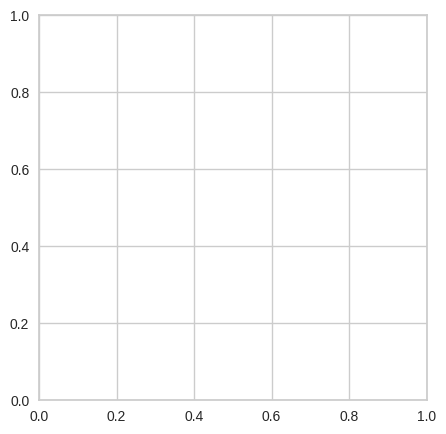

In [810]:
plt.figure(figsize=(5,5));
RocCurveDisplay.from_predictions(lda_model_num, X_test_num_scaled,y_test, pos_label=0, ax=plt.subplot());

plt.figure(figsize=(5,5));
RocCurveDisplay.from_predictions(lda_model_num, X_test_num_scaled,y_test, pos_label=0, ax=plt.subplot());

TODO: explicar conclusiones

ValueError: Expected 'estimator' to be a binary classifier. Got 3 classes instead.

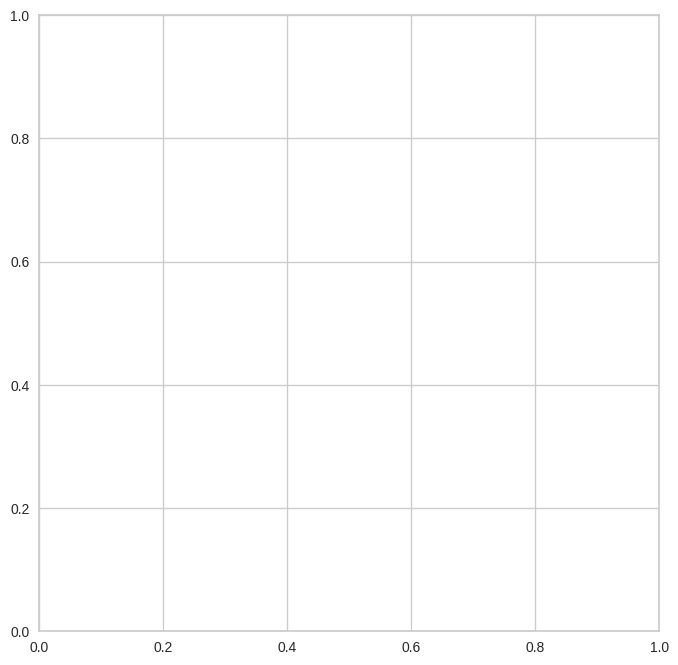

In [ ]:
# SOlucionar + add binarizado
#plt.figure(figsize=(8,8));
#PrecisionRecallDisplay.from_estimator(lda_model_num, X_test_num_scaled,y_test, pos_label=0, ax=plt.subplot());

In [ ]:
from apafib.yellowbrick.classifier.threshold import discrimination_threshold

discrimination_threshold(lda_model_num, X_train_num_scaled, y_train, is_fitted=True);

YellowbrickValueError: multiclass format is not supported

TODO: explicar resultados

Ahora podemos ver si el modelo de Naive Bayes supone una mejora sobre este.

### NAIVE BAYES

--------------------------------------------------------------

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Definimos la función de evaluación basándonos en el Laboratorio 4
# Usamos average='macro' para lidiar con el desbalanceo de clases
def save_results(clf, X_test, y_test, nclf, df):
    if hasattr(clf, 'best_score_'):
        df.loc[nclf,'train XV F1 (M)'] = clf.best_score_
    else:
        df.loc[nclf,'train XV F1 (M)'] = np.nan
        
    y_pred = clf.predict(X_test)
    df.loc[nclf,'test acc'] = accuracy_score(y_test, y_pred)
    df.loc[nclf,'precision score (M)'] = precision_score(y_test, y_pred, average='macro', zero_division=0)
    df.loc[nclf,'recall score (M)'] = recall_score(y_test, y_pred, average='macro', zero_division=0)
    df.loc[nclf,'f1 score (M)'] = f1_score(y_test, y_pred, average='macro', zero_division=0)
    return df

# Inicializamos el dataframe para guardar los resultados
results_df = pd.DataFrame()

# Escalado de datos (necesario para LDA y útil para GaussianNB)
scaler = StandardScaler()
X_train_num_sc = scaler.fit_transform(X_train_num)
X_test_num_sc = scaler.transform(X_test_num)

X_train_bin_sc = scaler.fit_transform(X_train_bin)
X_test_bin_sc = scaler.transform(X_test_bin)

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Hiperparámetros a explorar para LDA
params_lda = {'solver': ['svd', 'lsqr']}

# 1.1 LDA sobre Conjunto Numérico
grid_lda_num = GridSearchCV(LinearDiscriminantAnalysis(), params_lda, cv=5, scoring='f1_macro')
grid_lda_num.fit(X_train_num_sc, y_train)
results_df = save_results(grid_lda_num, X_test_num_sc, y_test, 'LDA - Numérico', results_df)

# 1.2 LDA sobre Conjunto Binarizado
grid_lda_bin = GridSearchCV(LinearDiscriminantAnalysis(), params_lda, cv=5, scoring='f1_macro')
grid_lda_bin.fit(X_train_bin_sc, y_train)
results_df = save_results(grid_lda_bin, X_test_bin_sc, y_test, 'LDA - Binarizado', results_df)

print("Mejores parámetros LDA Numérico:", grid_lda_num.best_params_)
print("Mejores parámetros LDA Binarizado:", grid_lda_bin.best_params_)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearDiscriminantAnalysis()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'solver': ['svd', 'lsqr']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, wit

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearDiscriminantAnalysis()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'solver': ['svd', 'lsqr']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, wit

Mejores parámetros LDA Numérico: {'solver': 'svd'}
Mejores parámetros LDA Binarizado: {'solver': 'svd'}


In [ ]:
from sklearn.naive_bayes import GaussianNB, BernoulliNB

# 2.1 Naive Bayes sobre Conjunto Numérico (GaussianNB)
# Exploramos el parámetro var_smoothing (estabilidad del cálculo de varianza)
params_gnb = {'var_smoothing': np.logspace(-9, -3, 7)}
grid_gnb_num = GridSearchCV(GaussianNB(), params_gnb, cv=5, scoring='f1_macro')
grid_gnb_num.fit(X_train_num_sc, y_train)
results_df = save_results(grid_gnb_num, X_test_num_sc, y_test, 'GaussianNB - Numérico', results_df)

# 2.2 Naive Bayes sobre Conjunto Binarizado (BernoulliNB)
# Ideal para variables dummy/booleanas. 
# NOTA: Usamos el conjunto BINARIZADO SIN ESCALAR, ya que BernoulliNB requiere datos discretos {0, 1}
params_bnb = {'alpha': [0.01, 0.1, 0.5, 1.0]} # Parámetro de suavizado de Laplace/Lidstone
grid_bnb_bin = GridSearchCV(BernoulliNB(), params_bnb, cv=5, scoring='f1_macro')
grid_bnb_bin.fit(X_train_bin, y_train)
results_df = save_results(grid_bnb_bin, X_test_bin, y_test, 'BernoulliNB - Binarizado', results_df)

print("Mejores parámetros GaussianNB Numérico:", grid_gnb_num.best_params_)
print("Mejores parámetros BernoulliNB Binarizado:", grid_bnb_bin.best_params_)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GaussianNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'var_smoothing': array([1.e-09...e-04, 1.e-03])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fittin

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",BernoulliNB()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues 

Mejores parámetros GaussianNB Numérico: {'var_smoothing': np.float64(1e-09)}
Mejores parámetros BernoulliNB Binarizado: {'alpha': 0.5}


,train XV F1 (M),test acc,precision score (M),recall score (M),f1 score (M)
LDA - Numérico,0.932,0.973,0.966,0.934,0.949
LDA - Binarizado,0.922,0.961,0.944,0.877,0.906
GaussianNB - Numérico,0.855,0.916,0.871,0.904,0.887
BernoulliNB - Binarizado,0.539,0.663,0.567,0.558,0.561


Text(0.5, 1.0, 'Matriz de Confusión: LDA - Numérico')

Text(0.5, 1.0, 'Matriz de Confusión: BernoulliNB - Binarizado')

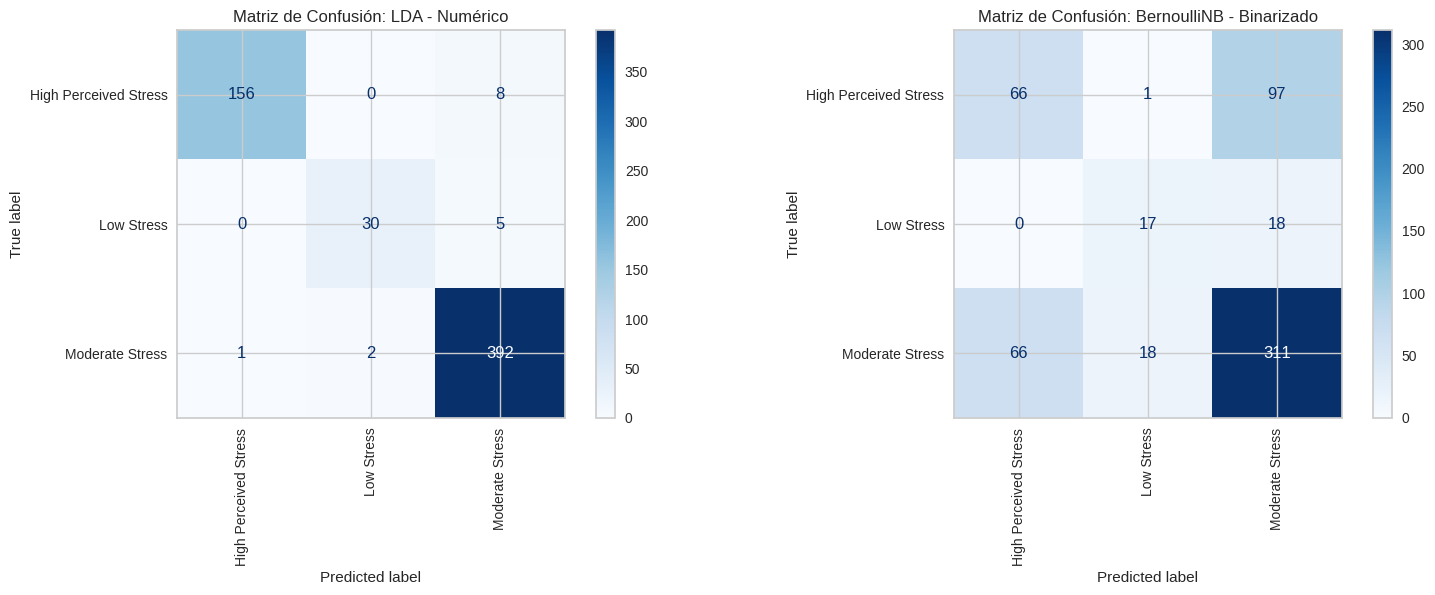

In [ ]:
# Ordenar los resultados por la métrica más robusta al desbalanceo (F1 Macro en Test)
display(results_df.sort_values(by='f1 score (M)', ascending=False))

# Visualización de Matrices de Confusión de los mejores modelos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz de Confusión para LDA (Asumiendo que Numérico suele comportarse bien)
ConfusionMatrixDisplay.from_estimator(
    grid_lda_num, X_test_num_sc, y_test, 
    ax=axes[0], cmap='Blues', xticks_rotation='vertical'
)
axes[0].set_title('Matriz de Confusión: LDA - Numérico')

# Matriz de Confusión para Naive Bayes (BernoulliNB)
ConfusionMatrixDisplay.from_estimator(
    grid_bnb_bin, X_test_bin, y_test, 
    ax=axes[1], cmap='Blues', xticks_rotation='vertical'
)
axes[1].set_title('Matriz de Confusión: BernoulliNB - Binarizado')

plt.tight_layout()
plt.show()